# Who Gets Remembered?
### Gender, scientific impact and visibility on scientists' Wikipedia pages
DTU 02805 Social Graphs and Interactions · final project

**Research question.** Are women scientists less central in Wikipedia's link network, and described differently on their pages, than men with similar scientific impact?

* **RQ1 · Network:** at equal impact, do women's pages have lower in-degree and PageRank?
* **RQ2 · Text:** at equal impact, are women's pages written differently?
* **RQ3 · Structure:** who links to women's pages, and where do women sit in the network's communities?

**How to run.** Open this notebook from the project folder with the project's virtual environment. By default, `RUN_DOWNLOADS = False`: the notebook reuses the data already saved in `data/`, because downloading it again takes several hours and depends on rate-limited APIs. Every analysis step below runs locally.

The same code also exists as standalone scripts in `src/` (`01_…` to `08_…`).

In [1]:
RUN_DOWNLOADS = False   # True = query Wikidata / Wikipedia / OpenAlex again (hours)

import warnings
warnings.filterwarnings('ignore')
from IPython.display import Image, Markdown, display

## 0 · Shared helpers
Paths, a polite HTTP client (retries, back-off, a throttle for Wikimedia), the scope of the study, and the **data log**: every query is written to `data/data_log.csv` with its date and the number of records returned.

In [2]:
import csv
import datetime as dt
import os
import time
from pathlib import Path

import requests

ROOT = Path.cwd()  # run the notebook from the project folder
RAW = ROOT / "data" / "raw"
PROC = ROOT / "data" / "processed"
LOG = ROOT / "data" / "data_log.csv"
for d in (RAW, PROC, RAW / "wikitext"):
    d.mkdir(parents=True, exist_ok=True)

UA = "SGI-WhoGetsRemembered/0.1 (DTU 02805 course project; python-requests)"
SESSION = requests.Session()
SESSION.headers["User-Agent"] = UA

# Scope (Phase 0). Edit here, then re-run the pipeline.
BIRTH_MIN, BIRTH_MAX = 1920, 1980
FIELDS = {  # Wikidata occupation QID -> field label
    "Q169470": "physics",
    "Q593644": "chemistry",
    "Q864503": "biology",  # robustness field (Phase 5)
}
MAIN_FIELDS = {"physics", "chemistry"}


_last = {"t": 0.0}
MIN_INTERVAL = {"wikipedia.org": 1.0}  # seconds between requests (Wikimedia rate limits unauthenticated clients)


def _throttle(url):
    for host, gap in MIN_INTERVAL.items():
        if host in url:
            wait = _last["t"] + gap - time.time()
            if wait > 0:
                time.sleep(wait)
            _last["t"] = time.time()


def get(url, params=None, retries=5, pause=0.0, **kw):
    """GET with retry/backoff on 429/5xx."""
    for i in range(retries):
        _throttle(url)
        try:
            r = SESSION.get(url, params=params, timeout=120, **kw)
        except requests.RequestException:
            time.sleep(2 ** i)
            continue
        if r.status_code == 200:
            if pause:
                time.sleep(pause)
            return r
        if r.status_code in (429, 500, 502, 503, 504):
            wait = float(r.headers.get("Retry-After", 2 ** (i + 1)))
            time.sleep(min(wait, 60))
            continue
        r.raise_for_status()
    raise RuntimeError(f"Failed after {retries} tries: {url} {params}")


def log(source, query, n_records, note=""):
    """Append one line to data/data_log.csv (every query, its date, records returned)."""
    new = not LOG.exists()
    with open(LOG, "a", newline="") as f:
        w = csv.writer(f)
        if new:
            w.writerow(["timestamp_utc", "source", "query", "n_records", "note"])
        w.writerow([dt.datetime.now(dt.timezone.utc).isoformat(timespec="seconds"),
                    source, query, n_records, note])


def openalex_params(extra=None):
    p = dict(extra or {})
    key = os.environ.get("OPENALEX_API_KEY")
    if key:
        p["api_key"] = key
    return p


## 1 · Data collection
### 1a · Who is in the dataset: Wikidata

**Scope.** Physicists (Q169470) and chemists (Q593644) born 1920–1980 with an English Wikipedia page; biologists (Q864503) are collected for the robustness check. Gender comes from P21; we compare only `male` and `female`, and other values are kept as network nodes but left out of the comparisons.

In [3]:
import pandas as pd


ENDPOINT = "https://query.wikidata.org/sparql"

TEMPLATE = """
SELECT ?p ?title ?birth
       (GROUP_CONCAT(DISTINCT ?g; separator="|") AS ?genders)
       (SAMPLE(?orcid_) AS ?orcid) (SAMPLE(?oa_) AS ?openalex)
       (SAMPLE(?label_) AS ?label)
WHERE {
  ?p wdt:P106 wd:%(occ)s; wdt:P31 wd:Q5; wdt:P569 ?b .
  BIND(YEAR(?b) AS ?birth)
  FILTER(?birth >= %(bmin)d && ?birth <= %(bmax)d)
  ?a schema:about ?p; schema:isPartOf <https://en.wikipedia.org/>; schema:name ?title .
  OPTIONAL { ?p wdt:P21 ?g }
  OPTIONAL { ?p wdt:P496 ?orcid_ }
  OPTIONAL { ?p wdt:P10283 ?oa_ }
  OPTIONAL { ?p rdfs:label ?label_ FILTER(LANG(?label_) = "en") }
} GROUP BY ?p ?title ?birth
"""

GENDER = {"Q6581097": "male", "Q6581072": "female"}


def collect_wikidata():
    frames = []
    for occ, field in FIELDS.items():
        q = TEMPLATE % {"occ": occ, "bmin": BIRTH_MIN, "bmax": BIRTH_MAX}
        r = get(ENDPOINT, params={"query": q, "format": "json"})
        rows = []
        for b in r.json()["results"]["bindings"]:
            gs = [g.rsplit("/", 1)[-1] for g in b.get("genders", {}).get("value", "").split("|") if g]
            labels = {GENDER.get(g, "other") for g in gs}
            gender = labels.pop() if len(labels) == 1 else ("missing" if not labels else "multiple")
            rows.append({
                "qid": b["p"]["value"].rsplit("/", 1)[-1],
                "title": b["title"]["value"],
                "label": b.get("label", {}).get("value"),
                "birth_year": int(float(b["birth"]["value"])),
                "gender": gender,
                "orcid": b.get("orcid", {}).get("value"),
                "openalex_wd": b.get("openalex", {}).get("value"),
                "field": field,
            })
        df = pd.DataFrame(rows)
        log("Wikidata SPARQL", f"occupation={occ} ({field}), birth {BIRTH_MIN}-{BIRTH_MAX}, enwiki page", len(df))
        print(f"{field}: {len(df)} people")
        frames.append(df)

    df = pd.concat(frames)
    # People with several occupations appear in several fields: keep one row, list all fields.
    fields = df.groupby("qid")["field"].apply(lambda s: "|".join(sorted(set(s))))
    df = df.drop_duplicates("qid").drop(columns="field").merge(fields, on="qid")
    # Some people share a birth-year-ambiguous record; keep the first.
    df = df.drop_duplicates("title")
    df.to_csv(PROC / "scientists_wikidata.csv", index=False)
    print(df.groupby("gender").size())
    print(f"Total unique people: {len(df)}; with ORCID: {df.orcid.notna().sum()}; "
          f"with OpenAlex ID: {df.openalex_wd.notna().sum()}")
    log("Wikidata SPARQL", "merged unique people across fields", len(df))


In [4]:
if RUN_DOWNLOADS:
    collect_wikidata()
people = pd.read_csv(PROC / 'scientists_wikidata.csv')
print(len(people), 'people'); people.gender.value_counts()

12773 people


gender
male        10479
female       2279
other          11
multiple        3
missing         1
Name: count, dtype: int64

### 1b · Wikipedia: pages, links and text

Raw wikitext for every page. Links are resolved through redirects and kept only when they point to another scientist in the set, which gives a **directed network**. Plain text is produced with reference-type sections (References, Publications, …) removed. *Most physics/chemistry pages were downloaded by a teammate on 11 Nov 2026 and merged; the rest were fetched on 13 Nov.*

In [5]:
import re
import json

import mwparserfromhell as mwp
import pandas as pd
from tqdm import tqdm


WP_API = "https://en.wikipedia.org/w/api.php"
WT = RAW / "wikitext"
TXT = PROC / "text"
TXT.mkdir(exist_ok=True)

DROP_SECTIONS = {"references", "notes", "external links", "further reading", "see also",
                 "bibliography", "sources", "citations", "footnotes", "notes and references",
                 "selected publications", "publications", "selected works", "works",
                 "selected bibliography", "references and notes"}


def norm(t):
    t = t.split("#", 1)[0].replace("_", " ").strip()
    t = re.sub(r"\s+", " ", t)
    return t[:1].upper() + t[1:] if t else t


def chunks(xs, n=50):
    for i in range(0, len(xs), n):
        yield xs[i:i + n]


def _fetch_one(qid, title):
    """Raw wikitext for one page; follows one redirect level if the sitelink is a redirect."""
    for _ in range(2):
        r = get("https://en.wikipedia.org/w/index.php", params={"title": title, "action": "raw"})
        m = re.match(r"#REDIRECT\s*\[\[([^\]|#]+)", r.text, re.I)
        if not m:
            (WT / f"{qid}.wiki").write_text(r.text)
            return True
        title = m.group(1)
    return False


def fetch_wikitext(people, workers=4):
    # Single-page raw fetches with a few parallel workers: multi-title prop=revisions
    # took ~45 s per 50 pages, this takes ~0.5 s per page.
    from concurrent.futures import ThreadPoolExecutor
    todo = people[~people.qid.map(lambda q: (WT / f"{q}.wiki").exists())]
    fails = 0
    with ThreadPoolExecutor(workers) as ex:
        futs = [ex.submit(_fetch_one, q, t) for q, t in zip(todo.qid, todo.title)]
        for f in tqdm(futs, desc="wikitext", mininterval=30):
            try:
                fails += not f.result()
            except Exception:
                fails += 1
    log("Wikipedia", "index.php?action=raw for all scientist titles",
        sum(1 for _ in WT.glob("*.wiki")), f"failed={fails}")


def fetch_redirects(people):
    out = PROC / "redirects.csv"
    if out.exists():
        return pd.read_csv(out)
    rows = []
    for batch in tqdm(list(chunks(list(people.title))), desc="redirects"):
        cont = {}
        while True:
            r = get(WP_API, params={"action": "query", "prop": "redirects", "rdlimit": "max",
                                 "rdnamespace": 0, "titles": "|".join(batch), "format": "json",
                                 "formatversion": 2, "maxlag": 5, **cont}, pause=0.1)
            j = r.json()
            for p in j["query"]["pages"]:
                for rd in p.get("redirects", []):
                    rows.append({"redirect": rd["title"], "target": p["title"]})
            if "continue" not in j:
                break
            cont = j["continue"]
    df = pd.DataFrame(rows).drop_duplicates()
    df.to_csv(out, index=False)
    log("Wikipedia WP_API", "prop=redirects (ns 0) for all scientist titles", len(df))
    return df


def plain_text(code):
    """Strip wikitext to prose; drop reference-like sections, tables, infobox, refs."""
    keep = []
    for sec in code.get_sections(levels=[2], include_lead=True, flat=False):
        heads = sec.filter_headings()
        if heads and heads[0].title.strip_code().strip().lower() in DROP_SECTIONS:
            continue
        keep.append(str(sec))
    code = mwp.parse("\n".join(keep))
    for tag in code.filter_tags(recursive=True):
        if str(tag.tag).lower() in ("ref", "table", "gallery", "math", "references"):
            try:
                code.remove(tag)
            except ValueError:
                pass
    for tpl in code.filter_templates(recursive=False):
        try:
            code.remove(tpl)
        except ValueError:
            pass
    text = code.strip_code(normalize=True, collapse=True)
    text = re.sub(r"\[\[(File|Image|Category):[^\]]*\]\]", "", text, flags=re.I)
    text = re.sub(r"^\s*(thumb|left|right|upright)\|.*$", "", text, flags=re.M)
    text = re.sub(r"\n{3,}", "\n\n", text)
    return text.strip()


def build(people, redirects):
    canon = dict(zip(people.title.map(norm), people.qid))
    for a, b in zip(redirects.redirect, redirects.target):
        if norm(b) in canon:
            canon[norm(a)] = canon[norm(b)]
    edges, stats = set(), []
    for qid, title in tqdm(list(zip(people.qid, people.title)), desc="parse"):
        f = WT / f"{qid}.wiki"
        if not f.exists():
            continue
        raw = f.read_text()
        code = mwp.parse(raw)
        links = [norm(str(l.title)) for l in code.filter_wikilinks()]
        bad = {"file", "image", "category", "wikipedia", "template", "help", "portal", "wikt"}
        links = [l for l in links if l and l.split(":")[0].lower() not in bad]
        for l in links:
            t = canon.get(l)
            if t and t != qid:
                edges.add((qid, t))
        text = plain_text(code)
        (TXT / f"{qid}.txt").write_text(text)
        stats.append({"qid": qid, "title": title, "n_chars": len(text), "n_words": len(text.split()),
                      "n_links_all": len(set(links)),
                      "is_redirect_or_disambig": bool(re.match(r"#REDIRECT", raw, re.I)) or
                      bool(re.search(r"\{\{\s*(disambiguation|dab|hndis|set index)", raw, re.I))})
    e = pd.DataFrame(sorted(edges), columns=["source", "target"])
    e.to_csv(PROC / "edges.csv", index=False)
    pd.DataFrame(stats).to_csv(PROC / "pages.csv", index=False)
    log("derived", "edges from wikilinks within the scientist set (redirects resolved)", len(e))
    print(f"pages parsed: {len(stats)}, edges: {len(e)}")


In [6]:
if RUN_DOWNLOADS:
    fetch_wikitext(people)
    build(people, fetch_redirects(people))
edges = pd.read_csv(PROC / 'edges.csv')
print(len(edges), 'links between scientists\' pages')

12292 links between scientists' pages


### 1c · Scientific impact: OpenAlex

Citations, works and h-index, matched **only through identifiers stored in Wikidata** (OpenAlex ID, then ORCID). We do not match by name, because of name ambiguity and the API budget. When one ORCID maps to several split OpenAlex profiles, their counts are added up and flagged.

*Captures:* an independent measure of impact. *Misses:* people without an ORCID, who are older and more often men, so the matched set is younger than the full set. *Check:* a hand-check of 100 matches (section 2).

In [7]:
import difflib
import json
import unicodedata

import pandas as pd
from tqdm import tqdm


OA_API = "https://api.openalex.org/authors"
OA_CACHE = RAW / "openalex_authors.jsonl"
SELECT = "id,orcid,display_name,display_name_alternatives,works_count,cited_by_count,summary_stats,topics"


def oa_chunks(xs, n=50):
    for i in range(0, len(xs), n):
        yield xs[i:i + n]


def fetch(filter_key, values):
    out = []
    for batch in tqdm(list(oa_chunks(values)), desc=filter_key):
        r = get(OA_API, params=openalex_params({"filter": f"{filter_key}:" + "|".join(batch),
                                             "per-page": 200, "select": SELECT}), pause=0.1)
        out += r.json()["results"]
    log("OpenAlex OA_API", f"/authors filter={filter_key} for {len(values)} ids", len(out))
    return out


def simplify(s):
    s = unicodedata.normalize("NFKD", str(s)).encode("ascii", "ignore").decode().lower()
    return " ".join(w for w in s.replace(".", " ").replace("-", " ").split() if len(w) > 1)


def name_sim(a, names):
    a = simplify(a)
    return max((difflib.SequenceMatcher(None, a, simplify(n)).ratio() for n in names if n), default=0)


def collect_openalex():
    people = pd.read_csv(PROC / "scientists_wikidata.csv")
    # Wikidata P10283 holds some non-author IDs (concepts, publishers) and lowercase variants.
    people["oa_clean"] = (people.openalex_wd.str.rsplit("/", n=1).str[-1].str.upper()
                          .where(lambda s: s.str.fullmatch(r"A\d+", na=False)))
    if OA_CACHE.exists():
        authors = [json.loads(l) for l in OA_CACHE.open()]
    else:
        oa_ids = sorted(set(people.oa_clean.dropna()))
        orcids = sorted(set(people.orcid.dropna()))
        authors = fetch("openalex", oa_ids) + fetch("orcid", orcids)
        with OA_CACHE.open("w") as f:
            for a in authors:
                f.write(json.dumps(a) + "\n")

    by_oa = {a["id"].rsplit("/", 1)[-1]: a for a in authors}
    by_orcid = {}
    for a in authors:
        if a.get("orcid"):
            by_orcid.setdefault(a["orcid"].rsplit("/", 1)[-1], []).append(a)

    rows = []
    for p in people.itertuples():
        cand, method = [], None
        if isinstance(p.oa_clean, str) and p.oa_clean in by_oa:
            cand, method = [by_oa[p.oa_clean]], "openalex_id"
        elif isinstance(p.orcid, str) and p.orcid in by_orcid:
            cand, method = by_orcid[p.orcid], "orcid"
        if not cand:
            continue
        # Several OpenAlex profiles can share an ORCID (split profiles): sum them, flag it.
        best = max(cand, key=lambda a: a["works_count"])
        names = [best["display_name"]] + (best.get("display_name_alternatives") or [])
        topics = best.get("topics") or []
        rows.append({
            "qid": p.qid, "openalex_id": best["id"].rsplit("/", 1)[-1], "match_method": method,
            "n_profiles": len(cand),
            "citations": sum(a["cited_by_count"] for a in cand),
            "works": sum(a["works_count"] for a in cand),
            "h_index": (best.get("summary_stats") or {}).get("h_index"),
            "oa_name": best["display_name"],
            "name_similarity": round(name_sim(p.label or p.title, names), 3),
            "top_field": topics[0]["field"]["display_name"] if topics else None,
            "top_subfield": topics[0]["subfield"]["display_name"] if topics else None,
        })
    df = pd.DataFrame(rows)
    df.to_csv(PROC / "impact.csv", index=False)
    log("derived", "impact.csv: people matched to OpenAlex by ID", len(df))
    m = people.merge(df, on="qid")
    print(m.groupby("gender").size())
    print("low name similarity (<0.6):", (df.name_similarity < 0.6).sum(),
          "| multi-profile ORCIDs:", (df.n_profiles > 1).sum())


In [8]:
if RUN_DOWNLOADS:
    collect_openalex()
impact = pd.read_csv(PROC / 'impact.csv')
print(len(impact), 'people matched'); impact.match_method.value_counts()

4146 people matched


match_method
orcid          4077
openalex_id      69
Name: count, dtype: int64

### 1d · Extra attributes: awards, Nobel prizes, deceased

Number of awards (P166), a Nobel flag, and whether the person has died (P570). Prizes are a **mediator**: women receive fewer, and Nobel laureates attract many links, so the analysis is also run without them.

*Pageviews and in-links from all of Wikipedia were planned as extra visibility measures but dropped: Wikimedia rate-limited us (HTTP 429). We list this as a limitation.*

In [9]:
import json
import sys
import threading
from concurrent.futures import ThreadPoolExecutor

import pandas as pd
from tqdm import tqdm


NOBEL = {"Q38104": "physics", "Q44585": "chemistry", "Q80061": "medicine"}
_lock = threading.Lock()


def people():
    return pd.read_csv(PROC / "scientists_wikidata.csv")


def awards():
    p = people()
    rows = []
    q = """SELECT ?p (COUNT(DISTINCT ?aw) AS ?n_awards) (GROUP_CONCAT(DISTINCT ?nb; separator="|") AS ?nobel)
                  (SAMPLE(?d) AS ?death) WHERE {
             VALUES ?p { %s }
             OPTIONAL { ?p wdt:P166 ?aw }
             OPTIONAL { ?p wdt:P166 ?nb . VALUES ?nb { wd:Q38104 wd:Q44585 wd:Q80061 } }
             OPTIONAL { ?p wdt:P570 ?d }
           } GROUP BY ?p"""
    ids = list(p.qid)
    for i in tqdm(range(0, len(ids), 300), desc="awards"):
        vals = " ".join(f"wd:{x}" for x in ids[i:i + 300])
        r = get("https://query.wikidata.org/sparql", params={"query": q % vals, "format": "json"}, pause=0.5)
        for b in r.json()["results"]["bindings"]:
            nob = [x.rsplit("/", 1)[-1] for x in b.get("nobel", {}).get("value", "").split("|") if x]
            rows.append({"qid": b["p"]["value"].rsplit("/", 1)[-1], "n_awards": int(b["n_awards"]["value"]),
                         "nobel": int(bool(nob)), "nobel_fields": "|".join(NOBEL[n] for n in nob),
                         "deceased": int("death" in b)})
    df = pd.DataFrame(rows)
    df.to_csv(PROC / "awards.csv", index=False)
    log("Wikidata SPARQL", "P166 awards, Nobel flag, P570 death for all people", len(df),
        f"nobel={df.nobel.sum()}, deceased={df.deceased.sum()}")
    print(df[["n_awards", "nobel", "deceased"]].describe().loc[["mean", "max"]])


def _cached_parallel(name, items, fn, workers=4):
    """Run fn(qid, title) -> dict for each item, caching one JSON line per item."""
    cache = RAW / f"{name}.jsonl"
    done = {}
    if cache.exists():
        for line in cache.open():
            d = json.loads(line)
            done[d["qid"]] = d
    todo = [(q, t) for q, t in items if q not in done]

    def run(q, t):
        try:
            d = {"qid": q, **fn(t)}
        except Exception as e:  # keep going; failures are logged and retried on the next run
            return {"qid": q, "error": str(e)[:200]}
        with _lock, cache.open("a") as f:
            f.write(json.dumps(d) + "\n")
        return d

    errors = 0
    with ThreadPoolExecutor(workers) as ex:
        for d in tqdm(ex.map(lambda x: run(*x), todo), total=len(todo), desc=name, mininterval=20):
            if "error" in d:
                errors += 1
            else:
                done[d["qid"]] = d
    return pd.DataFrame(done.values()), errors


def views():
    """Daily user pageviews, last 60 days, via the PageViewInfo API (50 titles per request).
    The per-article REST endpoint rate-limited us (HTTP 429), so we use this batched source instead."""
    p = people()
    by_title = dict(zip(p.title, p.qid))
    titles = list(p.title)
    cache = RAW / "pageviews_60d.jsonl"
    rows = {}
    if cache.exists():
        for line in cache.open():
            d = json.loads(line)
            rows[d["qid"]] = d
    done_titles = {t for t in titles if by_title[t] in rows}
    titles = [t for t in titles if t not in done_titles]
    print(f"pageviews: {len(rows)} cached, {len(titles)} to fetch", flush=True)
    for i in range(0, len(titles), 50):
        if i % 1000 == 0:
            print(f"  {i}/{len(titles)}", flush=True)
        batch, cont = titles[i:i + 50], {}
        while True:
            r = get("https://en.wikipedia.org/w/api.php",
                    params={"action": "query", "prop": "pageviews", "titles": "|".join(batch), "pvipdays": 60,
                            "redirects": 1, "format": "json", "formatversion": 2, "maxlag": 5, **cont}, pause=0.1)
            j = r.json()
            q = j["query"]
            alias = {x["from"]: x["to"] for x in q.get("normalized", []) + q.get("redirects", [])}
            back = {}
            for t in batch:
                c = t
                while c in alias:
                    c = alias[c]
                back[c] = t
            for pg in q["pages"]:
                if "pageviews" in pg:
                    qid = by_title.get(back.get(pg["title"], pg["title"]))
                    if qid:
                        rows[qid] = {"qid": qid, "pageviews_60d": sum(v or 0 for v in pg["pageviews"].values()),
                                     "pageview_days": len(pg["pageviews"])}
                        with cache.open("a") as fh:
                            fh.write(json.dumps(rows[qid]) + "\n")
            if "continue" not in j:
                break
            cont = j["continue"]
    df = pd.DataFrame(rows.values())
    df.to_csv(PROC / "pageviews.csv", index=False)
    log("Wikipedia API", "prop=pageviews (PageViewInfo), last 60 days, all people", len(df))
    print("pageviews:", len(df), "of", len(p), "median:", df.pageviews_60d.median())


def _backlinks(title):
    n, cont = 0, {}
    while True:
        r = get("https://en.wikipedia.org/w/api.php",
                params={"action": "query", "list": "backlinks", "bltitle": title, "blnamespace": 0,
                        "bllimit": "max", "blredirect": 1, "blfilterredir": "nonredirects",
                        "format": "json", "formatversion": 2, "maxlag": 5, **cont})
        j = r.json()
        for b in j["query"]["backlinks"]:
            n += 1 + len(b.get("redirlinks", []))
        if "continue" not in j:
            return {"backlinks_enwiki": n}
        cont = j["continue"]


def backlinks():
    """Only for people matched to OpenAlex (the comparison set); full-wiki in-links are a robustness check."""
    p = people().merge(pd.read_csv(PROC / "impact.csv")[["qid"]], on="qid")
    df, err = _cached_parallel("backlinks", list(zip(p.qid, p.title)), _backlinks, workers=1)
    df[["qid", "backlinks_enwiki"]].to_csv(PROC / "backlinks.csv", index=False)
    log("Wikipedia API", "list=backlinks (ns 0, incl. via redirects) for matched people", len(df), f"errors={err}")
    print("backlinks:", len(df), "errors:", err, "median:", df.backlinks_enwiki.median())


In [10]:
if RUN_DOWNLOADS:
    awards()
pd.read_csv(PROC / 'awards.csv')[['n_awards', 'nobel', 'deceased']].mean().round(3)

n_awards    2.286
nobel       0.021
deceased    0.382
dtype: float64

## 2 · Cleaning, strata and match quality

Merge everything, remove redirects, disambiguation pages and stubs, and define the **strata** used in every comparison: field × birth decade (× impact bin in RQ1). The hand-check of 100 random matches (50 women, 50 men) is summarised with Wilson 95% intervals, separately by gender.

In [11]:
import numpy as np
import pandas as pd


SEED = 2805


def wilson(k, n, z=1.96):
    p = k / n
    c = (p + z * z / (2 * n)) / (1 + z * z / n)
    h = z * np.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / (1 + z * z / n)
    return c - h, c + h


def field_group(fields):
    fs = set(fields.split("|"))
    main = fs & MAIN_FIELDS
    if main == {"physics", "chemistry"}:
        return "phys+chem"
    if main:
        return main.pop()
    return "biology"


def optional(name, cols):
    f = PROC / name
    if f.exists():
        return pd.read_csv(f)
    print(f"  (note: {name} not found yet; columns {cols} will be missing)")
    return pd.DataFrame(columns=["qid"] + cols)


def clean_and_merge():
    people = pd.read_csv(PROC / "scientists_wikidata.csv")
    pages = pd.read_csv(PROC / "pages.csv")
    impact = pd.read_csv(PROC / "impact.csv")
    edges = pd.read_csv(PROC / "edges.csv")
    rep = []

    def note(msg, n=""):
        rep.append(f"{msg}: {n}" if n != "" else msg)
        print(rep[-1])

    note("Wikidata people (all fields)", len(people))
    df = people.merge(pages.drop(columns="title"), on="qid", how="inner")
    note("with downloaded Wikipedia page", len(df))
    df = df[~df.is_redirect_or_disambig]
    note("after removing redirects / disambiguation pages", len(df))
    df = df[df.n_words >= 50]
    note("after removing stubs (< 50 words of prose)", len(df))

    df["gender_known"] = df.gender.isin(["male", "female"])
    df["field_group"] = df.field.map(field_group)
    df["main_field"] = df.field_group != "biology"
    df["birth_decade"] = (df.birth_year // 10 * 10).astype(int)

    df = (df.merge(impact, on="qid", how="left")
            .merge(optional("awards.csv", ["n_awards", "nobel", "nobel_fields", "deceased"]), on="qid", how="left")
            .merge(optional("pageviews.csv", ["pageviews_60d"]), on="qid", how="left")
            .merge(optional("backlinks.csv", ["backlinks_enwiki"]), on="qid", how="left"))
    df["matched"] = df.openalex_id.notna()
    df["match_doubtful"] = df.matched & (df.name_similarity < 0.6)
    df["usable"] = df.matched & ~df.match_doubtful & df.gender_known & (df.citations > 0)

    note("")
    note("Gender (all kept pages): " + ", ".join(f"{k}={v}" for k, v in df.gender.value_counts().items()))
    for scope, s in (("MAIN (physics/chemistry)", df[df.main_field]), ("BIOLOGY (robustness)", df[~df.main_field])):
        note(f"\n{scope}: pages", len(s))
        note("  matched to OpenAlex by ID", int(s.matched.sum()))
        note("  dropped as doubtful match (name similarity < 0.6)", int(s.match_doubtful.sum()))
        note("  usable for comparisons (matched, not doubtful, gender m/f, citations > 0)", int(s.usable.sum()))
        for g in ("female", "male"):
            gs = s[s.gender == g]
            note(f"    {g}: {int(gs.usable.sum())} usable of {len(gs)} pages "
                 f"({gs.usable.mean():.1%}); split OpenAlex profiles among matched: "
                 f"{(gs[gs.matched].n_profiles > 1).mean():.1%}; doubtful: {gs.match_doubtful.mean():.1%}")

    u = df[df.usable & df.main_field]
    note("\nUsable main set, per field x decade (women / men):")
    tab = u.groupby(["field_group", "birth_decade", "gender"]).size().unstack(fill_value=0)
    note(tab.to_string())

    df.to_csv(PROC / "nodes.csv", index=False)
    keep = set(df.qid)
    e = edges[edges.source.isin(keep) & edges.target.isin(keep)]
    e.to_csv(PROC / "edges_clean.csv", index=False)
    note("\nedges between kept pages", len(e))

    # Hand-check sample: 50 women + 50 men among matched main-field people, so accuracy is reported by gender.
    m = df[df.matched & df.gender_known & df.main_field]
    sample = pd.concat([g.sample(50, random_state=SEED) for _, g in m.groupby("gender")])
    sample = sample[["qid", "title", "gender", "birth_year", "field", "match_method", "oa_name", "openalex_id",
                     "citations", "works", "h_index", "top_field", "name_similarity", "n_profiles"]]
    sample["wikipedia_url"] = "https://en.wikipedia.org/wiki/" + sample.title.str.replace(" ", "_")
    sample["openalex_url"] = "https://openalex.org/" + sample.openalex_id
    sample["correct"] = ""           # 1 = same person, 0 = wrong person
    sample["profile_complete"] = ""  # 1 = OpenAlex profile looks complete, 0 = clearly missing works (e.g. name change)
    sample["comment"] = ""
    out = PROC / "handcheck_sample.csv"
    if out.exists():
        print("  handcheck_sample.csv exists: not overwritten (may contain labels)")
    else:
        sample.to_csv(out, index=False)

    hc = pd.read_csv(out)
    if hc["correct"].notna().all() and len(hc):
        note("\nHand-check of matches (Wilson 95% CI):")
        for g, x in [("all", hc)] + list(hc.groupby("gender")):
            for col in ("correct", "profile_complete"):
                k, n = int(x[col].sum()), len(x)
                lo, hi = wilson(k, n)
                note(f"  {g:<7} {col:<17} {k}/{n} = {k / n:.0%} [{lo:.0%}, {hi:.0%}]")

    (PROC / "cleaning_report.txt").write_text("\n".join(rep) + "\n")
    log("derived", "nodes.csv after cleaning", len(df), f"usable_main={len(u)}")


In [12]:
clean_and_merge()

Wikidata people (all fields): 12773
with downloaded Wikipedia page: 12759
after removing redirects / disambiguation pages: 12756
after removing stubs (< 50 words of prose): 12463
  (note: pageviews.csv not found yet; columns ['pageviews_60d'] will be missing)
  (note: backlinks.csv not found yet; columns ['backlinks_enwiki'] will be missing)

Gender (all kept pages): male=10194, female=2255, other=11, multiple=3

MAIN (physics/chemistry): pages: 9680
  matched to OpenAlex by ID: 3006
  dropped as doubtful match (name similarity < 0.6): 77
  usable for comparisons (matched, not doubtful, gender m/f, citations > 0): 2926
    female: 606 usable of 1464 pages (41.4%); split OpenAlex profiles among matched: 12.2%; doubtful: 1.6%
    male: 2320 usable of 8209 pages (28.3%); split OpenAlex profiles among matched: 15.5%; doubtful: 0.7%

BIOLOGY (robustness): pages: 2783
  matched to OpenAlex by ID: 1063
  dropped as doubtful match (name similarity < 0.6): 30
  usable for comparisons (matched, 


Hand-check of matches (Wilson 95% CI):
  all     correct           100/100 = 100% [96%, 100%]
  all     profile_complete  96/100 = 96% [90%, 98%]
  female  correct           50/50 = 100% [93%, 100%]
  female  profile_complete  49/50 = 98% [90%, 100%]
  male    correct           50/50 = 100% [93%, 100%]
  male    profile_complete  47/50 = 94% [84%, 98%]


## 3 · Network analysis (RQ1, RQ3)

**RQ1: visibility at equal impact.**
* *Null model:* gender labels are shuffled 1,000 times **within strata** of field × birth decade × citation quintile. The statistic is the within-stratum gap in mean log outcome (women − men), weighted by the number of women.
* *Regression:* log outcome ~ female + log citations + field + birth decade + deceased (HC3 95% CI); a second model adds Nobel + awards to see how much of the gap runs through prizes.
* *Two-part split:* (1) does a page get **any** in-link from another scientist's page, and (2) PageRank among pages that do.

*Captures:* visibility inside Wikipedia relative to impact. *Misses:* why links exist (editors, topics); citations carry their own gender gap, so we estimate the gap **on top of** existing inequality.

**RQ3: structure.** One testable quantity: the share of in-links to women's pages that come from women, against a null that shuffles gender within field × decade with the network held fixed. Louvain communities are **descriptive**: modularity is compared with a configuration-model null, and stability with NMI across 10 seeds.

In [13]:
import argparse
import json

import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd
import statsmodels.formula.api as smf
from sklearn.metrics import normalized_mutual_info_score


RES, FIG = ROOT / "results", ROOT / "figures"
RES.mkdir(exist_ok=True)
FIG.mkdir(exist_ok=True)
COL = {"female": "#C2410C", "male": "#1D4ED8", "other": "#9CA3AF"}
OUTCOMES = {  # column -> (transformed column, label)
    "pagerank": ("log_pr", "PageRank (log$_{10}$)"),
    "in_degree": ("log_indeg", "In-degree within network (log$_{10}$ 1+x)"),
    "pageviews_60d": ("log_views", "Pageviews, last 60 days (log$_{10}$ 1+x)"),
    "backlinks_enwiki": ("log_backlinks", "In-links from all of Wikipedia (log$_{10}$ 1+x)"),
    "n_words": ("log_words", "Page length, words (log$_{10}$)"),
}
IMPACT_LABEL = {"citations": "Citations", "h_index": "h-index", "works": "Works"}


# ---------------------------------------------------------------- data
def load_graph(fields):
    nodes = pd.read_csv(PROC / "nodes.csv")
    nodes = nodes[nodes.main_field] if fields == "main" else nodes[nodes.field_group == fields]
    edges = pd.read_csv(PROC / "edges_clean.csv")
    G = nx.DiGraph()
    G.add_nodes_from(nodes.qid)
    G.add_edges_from(edges[edges.source.isin(G) & edges.target.isin(G)].itertuples(index=False))
    nodes = nodes.set_index("qid")
    nodes["in_degree"] = pd.Series(dict(G.in_degree()))
    nodes["out_degree"] = pd.Series(dict(G.out_degree()))
    nodes["pagerank"] = pd.Series(nx.pagerank(G, alpha=0.85))
    return nodes, G


def comparison_set(nodes, impact="citations", bins=5, drop_nobel=False, drop_top1=False):
    d = nodes[nodes.usable & (nodes[impact] > 0)].copy()
    notes = {"start": len(d)}
    if drop_nobel:
        d = d[d.nobel.fillna(0) == 0]
        notes["after_drop_nobel"] = len(d)
    if drop_top1:
        d = d[d[impact] < d[impact].quantile(0.99)]
        notes["after_drop_top1pct"] = len(d)
    d["female"] = (d.gender == "female").astype(int)
    d["log_impact"] = np.log10(d[impact])
    d["impact_bin"] = pd.qcut(d.log_impact.rank(method="first"), bins, labels=False)
    d["stratum"] = d.field_group + "|" + d.birth_decade.astype(str) + "|" + d.impact_bin.astype(str)
    d["deceased"] = d.deceased.fillna(0)
    d["log_awards"] = np.log10(1 + d.n_awards.fillna(0))
    d["nobel"] = d.nobel.fillna(0)
    for col, (t, _) in OUTCOMES.items():
        if col in d and d[col].notna().any():
            d[t] = np.log10(d[col]) if col in ("pagerank", "n_words") else np.log10(1 + d[col])
    return d, notes


# ---------------------------------------------------------------- RQ1
def stratified_shuffle(d, y, runs, rng):
    """Within-stratum gender gap and its null distribution (labels shuffled within strata)."""
    s = d[[y, "female", "stratum"]].dropna()
    codes, strata = pd.factorize(s.stratum)
    yv, f = s[y].to_numpy(), s.female.to_numpy()
    k = len(strata)
    n_f = np.bincount(codes, weights=f, minlength=k)
    n_m = np.bincount(codes, minlength=k) - n_f
    ok = (n_f > 0) & (n_m > 0)  # strata with both genders
    tot = np.bincount(codes, weights=yv, minlength=k)

    def gap(fv):
        sf = np.bincount(codes, weights=yv * fv, minlength=k)
        g = sf[ok] / n_f[ok] - (tot[ok] - sf[ok]) / n_m[ok]
        return np.average(g, weights=n_f[ok])

    obs = gap(f)
    order = np.argsort(codes, kind="stable")
    bounds = np.r_[0, np.cumsum(np.bincount(codes, minlength=k))]
    null = np.empty(runs)
    for i in range(runs):
        fv = f[order].copy()
        for a, b in zip(bounds[:-1], bounds[1:]):
            fv[a:b] = rng.permutation(fv[a:b])
        out = np.empty_like(fv)
        out[order] = fv
        null[i] = gap(out)
    z = (obs - null.mean()) / null.std()
    p = (np.sum(np.abs(null - null.mean()) >= abs(obs - null.mean())) + 1) / (runs + 1)
    return {"n": int(len(s)), "women": int(f.sum()), "strata_used": int(ok.sum()), "strata_total": int(k),
            "women_in_used_strata": int(n_f[ok].sum()), "gap_log10": float(obs),
            "gap_ratio": float(10 ** obs),  # women's outcome as a multiple of men's (geometric mean)
            "null_mean": float(null.mean()), "null_sd": float(null.std()), "z": float(z), "p": float(p)}, null


def regression(d, y, with_prizes=False):
    f = f"{y} ~ female + log_impact + C(field_group) + C(birth_decade) + deceased"
    if with_prizes:
        f += " + nobel + log_awards"
    m = smf.ols(f, data=d.dropna(subset=[y])).fit(cov_type="HC3")
    lo, hi = m.conf_int().loc["female"]
    b = m.params["female"]
    return {"coef_female_log10": float(b), "ci95": [float(lo), float(hi)], "p": float(m.pvalues["female"]),
            "ratio": float(10 ** b), "ratio_ci95": [float(10 ** lo), float(10 ** hi)],
            "coef_log_impact": float(m.params["log_impact"]), "n": int(m.nobs), "r2": float(m.rsquared)}


def two_part(d):
    """PageRank gap split into (1) whether a page gets any in-link from another scientist's page and
    (2) PageRank among pages that do. Same covariates as the main regression."""
    d = d.assign(any_in=(d.in_degree > 0).astype(int))
    f = "~ female + log_impact + C(field_group) + C(birth_decade) + deceased"
    m1 = smf.ols("any_in " + f, data=d).fit(cov_type="HC3")
    lk = d[d.any_in == 1]
    m2 = smf.ols("log_pr " + f, data=lk).fit(cov_type="HC3")
    return {"share_any_inlink": d.groupby("gender").any_in.mean().to_dict(),
            "any_inlink_diff_female": float(m1.params["female"]),
            "any_inlink_diff_ci95": m1.conf_int().loc["female"].tolist(),
            "linked_only_pr_ratio": float(10 ** m2.params["female"]),
            "linked_only_pr_ratio_ci95": (10 ** m2.conf_int().loc["female"]).tolist(),
            "linked_only_n": int(len(lk)), "linked_only_women": int(lk.female.sum())}


def fig1(d, out, nulls, impact, tag):
    """(a) citations vs PageRank by gender, binned means with 95% CI, pages without in-links as a strip;
    (b) observed gap vs. stratified-shuffle null for every visibility outcome."""
    fig, (a, b) = plt.subplots(1, 2, figsize=(12.5, 5.2), gridspec_kw={"width_ratios": [1.7, 1]})
    linked = d.in_degree > 0
    floor = d.log_pr.min()
    rng = np.random.default_rng(0)
    for g in ("male", "female"):
        s = d[(d.gender == g) & linked]
        a.scatter(s.log_impact, s.log_pr, s=7, alpha=0.35, color=COL[g], lw=0)
        z = d[(d.gender == g) & ~linked]
        a.scatter(z.log_impact, floor - 0.25 + rng.uniform(-.08, .08, len(z)) + (0.1 if g == "female" else -0.1),
                  s=4, alpha=0.25, color=COL[g], lw=0)
    edges = np.quantile(d.log_impact, np.linspace(0, 1, 9))
    d = d.assign(xb=np.clip(np.digitize(d.log_impact, edges[1:-1]), 0, 7))
    for g, lab in (("male", "Men"), ("female", "Women")):
        s = d[d.gender == g].groupby("xb")
        m, se, x = s.log_pr.mean(), s.log_pr.sem(), s.log_impact.median()
        a.plot(x, m, color=COL[g], lw=2.6, marker="o", ms=4,
               label=f"{lab} (n={int((d.gender == g).sum()):,}), mean by citation octile")
        a.fill_between(x, m - 1.96 * se, m + 1.96 * se, color=COL[g], alpha=0.18, lw=0)
    a.axhline(floor - 0.12, color="#E5E7EB", lw=0.8)
    a.text(d.log_impact.min(), floor - 0.25, "no in-links from\nother scientists' pages", fontsize=7.5,
           color="#6B7280", va="center", ha="left")
    tp = out["two_part"]["share_any_inlink"]
    a.set_title(f"Pages with ≥1 in-link: women {tp['female']:.0%}, men {tp['male']:.0%}", fontsize=9.5, loc="left")
    a.set_xlabel(f"{IMPACT_LABEL[impact]} (log$_{{10}}$, OpenAlex)")
    a.set_ylabel("PageRank in scientist network (log$_{10}$)")
    a.legend(loc="upper left", frameon=False, fontsize=8.5)
    a.spines[["top", "right"]].set_visible(False)

    names = {"log_pr": "PageRank", "log_indeg": "In-degree", "log_views": "Pageviews (60 d)",
             "log_backlinks": "In-links, all Wikipedia", "log_words": "Page length"}
    keys = [k for k in names if k in nulls]
    col_of = {v[0]: k for k, v in OUTCOMES.items()}
    for i, k in enumerate(keys):
        nl = 10 ** nulls[k]
        lo, hi = np.percentile(nl, [2.5, 97.5])
        b.plot([lo, hi], [i, i], color="#D1D5DB", lw=9, solid_capstyle="butt")
        sh = out["shuffle"][col_of[k]]
        b.plot(sh["gap_ratio"], i, "o", color=COL["female"], ms=8)
        b.text(max(hi, sh["gap_ratio"]) + 0.012, i, f"z = {sh['z']:.1f}", va="center", fontsize=8, color="#374151")
    b.axvline(1, color="#9CA3AF", lw=0.8, ls=":")
    b.set_yticks(range(len(keys)), [names[k] for k in keys])
    b.invert_yaxis()
    b.set_xlabel("Women / comparable men (within field × decade × impact)")
    b.set_title("Observed (dot) vs. 95% of shuffled-gender nulls (bar)", fontsize=9.5, loc="left")
    b.spines[["top", "right", "left"]].set_visible(False)
    b.tick_params(axis="y", length=0)
    fig.tight_layout()
    fig.savefig(FIG / f"fig1_{tag}.png", dpi=200)
    plt.close(fig)


# ---------------------------------------------------------------- RQ3
def inlink_share_from_women(nodes, G, rng, runs=1000):
    known = nodes[nodes.gender_known]
    idx = {q: i for i, q in enumerate(known.index)}
    E = np.array([(idx[u], idx[v]) for u, v in G.edges() if u in idx and v in idx])
    fem = (known.gender == "female").to_numpy().astype(int)

    def stat(fv):
        to_w = fv[E[:, 1]] == 1
        to_m = ~to_w
        return fv[E[to_w, 0]].mean(), fv[E[to_m, 0]].mean()

    obs_w, obs_m = stat(fem)
    groups = [np.where(g)[0] for g in
              (known.field_group + "|" + known.birth_decade.astype(str)).pipe(
                  lambda s: [s.to_numpy() == v for v in s.unique()])]
    nw, nm = np.empty(runs), np.empty(runs)
    for i in range(runs):
        fv = fem.copy()
        for g in groups:
            fv[g] = rng.permutation(fv[g])
        nw[i], nm[i] = stat(fv)
    return {"edges_between_gender_known": int(len(E)),
            "share_women_among_linking_pages_overall": float(fem[E[:, 0]].mean()),
            "to_women": {"observed": float(obs_w), "null_mean": float(nw.mean()), "null_sd": float(nw.std()),
                         "z": float((obs_w - nw.mean()) / nw.std())},
            "to_men": {"observed": float(obs_m), "null_mean": float(nm.mean()), "null_sd": float(nm.std()),
                       "z": float((obs_m - nm.mean()) / nm.std())},
            "null": "gender shuffled within field x birth decade, network fixed"}


def communities(nodes, G, rng, seeds=10):
    U = G.to_undirected()
    U = U.subgraph(max(nx.connected_components(U), key=len)).copy()
    parts = [nx.community.louvain_communities(U, seed=s) for s in range(seeds)]
    order = list(U)
    lab = [[{n: i for i, c in enumerate(p) for n in c}[n] for n in order] for p in parts]
    nmi = [normalized_mutual_info_score(lab[0], l) for l in lab[1:]]
    Q = nx.community.modularity(U, parts[0])
    Qn = []
    for _ in range(5):
        R = nx.Graph(nx.configuration_model([k for _, k in U.degree()], seed=int(rng.integers(1e9))))
        R.remove_edges_from(nx.selfloop_edges(R))
        Qn.append(nx.community.modularity(R, nx.community.louvain_communities(R, seed=0)))
    # Within-community PageRank percentile, women vs men, for every seed (stability check).
    seed_stats = []
    for sd, p in enumerate(parts):
        cm = {n: i for i, c in enumerate(sorted(p, key=len, reverse=True)) for n in c}
        t = nodes.loc[order].assign(community=pd.Series(cm))
        t = t[t.gender_known]
        t["pct"] = t.groupby("community").pagerank.rank(pct=True)
        big = t.community.value_counts().pipe(lambda v: v[v >= 100].index)
        per = t[t.community.isin(big)].groupby(["community", "gender"]).pct.mean().unstack()
        seed_stats.append({"seed": sd, "mean_pct_women": float(t[t.gender == "female"].pct.mean()),
                           "mean_pct_men": float(t[t.gender == "male"].pct.mean()),
                           "communities_ge100": int(len(per)),
                           "communities_women_lower": int((per.female < per.male).sum())})
    comm = {n: i for i, c in enumerate(sorted(parts[0], key=len, reverse=True)) for n in c}
    cc = nodes.loc[order].assign(community=pd.Series(comm))
    cc["pct_in_comm"] = cc[cc.gender_known].groupby("community").pagerank.rank(pct=True)
    k = cc[cc.gender_known]
    tab = k.groupby("community").agg(
        size=("gender", "size"), share_women=("gender", lambda s: (s == "female").mean()),
        share_physics=("field_group", lambda s: (s == "physics").mean()),
        median_birth=("birth_year", "median"),
        hub=("pagerank", lambda s: cc.loc[s.idxmax(), "title"]))
    return {"lcc_nodes": U.number_of_nodes(), "n_communities": len(parts[0]), "modularity": Q,
            "modularity_config_null_mean": float(np.mean(Qn)), "nmi_vs_seed0_mean": float(np.mean(nmi)),
            "nmi_vs_seed0_min": float(np.min(nmi)), "within_community_rank_by_seed": seed_stats,
            "communities_ge_30": tab[tab["size"] >= 30].round(3).reset_index().to_dict("records")}, cc


def fig3(G, cc, tag, n_comm=9):
    """(a) the nine largest Louvain communities, each laid out separately on a 3x3 grid; colour = gender,
    size = citations; label = most central page + share of women.
    (b) mean within-community PageRank percentile of women vs. men, per community."""
    top = list(cc.community.value_counts().index[:n_comm])
    U = G.to_undirected()
    fig = plt.figure(figsize=(15, 9.5))
    a = fig.add_axes([0.0, 0.03, 0.64, 0.92])
    b = fig.add_axes([0.73, 0.12, 0.25, 0.76])
    cit_all = np.log10(cc.citations.fillna(0) + 1)
    names = []
    for i, k in enumerate(top):
        members = cc.index[cc.community == k]
        H = U.subgraph(members)
        pos = nx.spring_layout(H, k=1.2 / np.sqrt(len(H)), iterations=80, seed=1)
        off = np.array([i % 3, -(i // 3)]) * 2.6
        pos = {n: p + off for n, p in pos.items()}
        nx.draw_networkx_edges(H, pos, ax=a, alpha=0.05, width=0.3)
        for g in ("male", "other", "female"):
            ns = [n for n in H if (cc.loc[n, "gender"] if cc.loc[n, "gender"] in COL else "other") == g]
            nx.draw_networkx_nodes(H, pos, nodelist=ns, ax=a, node_color=COL[g], alpha=0.85, linewidths=0,
                                   node_size=[3 + 55 * (cit_all[n] / cit_all.max()) ** 2 for n in ns])
        sub = cc.loc[members]
        known = sub[sub.gender_known]
        hub = sub.pagerank.idxmax()
        names.append(sub.loc[hub, "title"])
        a.text(off[0], off[1] + 1.22, f"{chr(65 + i)}. {sub.loc[hub, 'title']}\n"
               f"{(known.gender == 'female').mean():.0%} women · n={len(sub)}",
               ha="center", fontsize=8.5, color="#111827")
    a.scatter([], [], color=COL["female"], label="Women", s=30)
    a.scatter([], [], color=COL["male"], label="Men", s=30)
    a.legend(loc="lower center", bbox_to_anchor=(0.5, -0.04), ncol=2, frameon=False)
    a.set_title("Nine largest link communities (Louvain) · label = most central page · size = citations",
                fontsize=10, pad=34)
    a.set_axis_off()

    k = cc[cc.gender_known & cc.community.isin(top)]
    per = k.groupby(["community", "gender"]).pct_in_comm.mean().unstack().loc[top]
    ys = np.arange(len(top))
    for y, (_, r) in zip(ys, per.iterrows()):
        b.plot([r.female, r.male], [y, y], color="#D1D5DB", lw=2, zorder=1)
    b.scatter(per.male, ys, color=COL["male"], s=40, zorder=2, label="Men")
    b.scatter(per.female, ys, color=COL["female"], s=40, zorder=2, label="Women")
    allk = cc[cc.gender_known]
    yo = len(top) + 0.6
    mw, mm = allk[allk.gender == "female"].pct_in_comm.mean(), allk[allk.gender == "male"].pct_in_comm.mean()
    b.plot([mw, mm], [yo, yo], color="#9CA3AF", lw=2.5)
    b.scatter([mm], [yo], color=COL["male"], s=60, marker="D")
    b.scatter([mw], [yo], color=COL["female"], s=60, marker="D")
    b.set_yticks(list(ys) + [yo], [f"{chr(65 + i)}. {n}" for i, n in enumerate(names)] + ["All communities"],
                 fontsize=8.5)
    b.invert_yaxis()
    b.axvline(0.5, color="#9CA3AF", lw=0.8, ls=":")
    b.set_xlim(0.2, 0.7)
    b.set_xlabel("Mean PageRank percentile within own community")
    b.set_title("Within every community, women sit\ncloser to the periphery", fontsize=10, loc="left")
    b.legend(frameon=False, loc="lower right", fontsize=8.5)
    b.spines[["top", "right", "left"]].set_visible(False)
    b.tick_params(axis="y", length=0)
    fig.savefig(FIG / f"fig3_{tag}.png", dpi=200, bbox_inches="tight")
    plt.close(fig)


# ---------------------------------------------------------------- main
def run_rq1(fields="main", impact="citations", bins=5, runs=1000, seed=2805, drop_nobel=False,
            drop_top1=False, nodes_G=None, figure=False):
    """Returns a dict of results. Importable by 08_robustness.py."""
    rng = np.random.default_rng(seed)
    nodes, G = nodes_G or load_graph(fields)
    d, notes = comparison_set(nodes, impact, bins, drop_nobel, drop_top1)
    tag = f"{fields}_{impact}_b{bins}_s{seed}" + ("_nonobel" if drop_nobel else "") + ("_notop1" if drop_top1 else "")
    out = {"config": dict(fields=fields, impact=impact, bins=bins, runs=runs, seed=seed,
                          drop_nobel=drop_nobel, drop_top1=drop_top1),
           "graph": {"nodes": G.number_of_nodes(), "edges": G.number_of_edges(),
                     "isolates": nx.number_of_isolates(G),
                     "largest_wcc": len(max(nx.weakly_connected_components(G), key=len))},
           "comparison_set": {**notes, "n": len(d), "women": int(d.female.sum()), "men": int((1 - d.female).sum())},
           "shuffle": {}, "regression": {}, "regression_with_prizes": {}}
    nulls, gaps = {}, {}
    for col, (y, _) in OUTCOMES.items():
        if y not in d:
            continue
        res, null = stratified_shuffle(d, y, runs, rng)
        out["shuffle"][col], nulls[y], gaps[y] = res, null, res["gap_log10"]
        out["regression"][col] = regression(d, y)
        out["regression_with_prizes"][col] = regression(d, y, with_prizes=True)
    out["two_part"] = two_part(d)
    if figure:
        fig1(d, out, nulls, impact, tag)
    (RES / f"rq1_{tag}.json").write_text(json.dumps(out, indent=2))
    log("analysis", f"RQ1 {tag}", len(d))
    return out, (nodes, G)


def summary(out):
    print(f"\nComparison set: {out['comparison_set']}")
    print(f"{'outcome':<18}{'shuffle gap (x)':>16}{'z':>8}{'p':>8}   {'regression ratio [95% CI]':<30}{'+prizes':>10}")
    for col, s in out["shuffle"].items():
        r, rp = out["regression"][col], out["regression_with_prizes"][col]
        print(f"{col:<18}{s['gap_ratio']:>16.3f}{s['z']:>8.2f}{s['p']:>8.3f}   "
              f"{r['ratio']:.3f} [{r['ratio_ci95'][0]:.3f}, {r['ratio_ci95'][1]:.3f}]{rp['ratio']:>12.3f}")
    print("(ratios = women's outcome as a multiple of comparable men's; < 1 means less visible)")
    t = out.get("two_part")
    if t:
        print(f"Two-part: any in-link women {t['share_any_inlink'].get('female', 0):.1%} vs men "
              f"{t['share_any_inlink'].get('male', 0):.1%}; adjusted diff {t['any_inlink_diff_female']:+.3f} "
              f"[{t['any_inlink_diff_ci95'][0]:+.3f}, {t['any_inlink_diff_ci95'][1]:+.3f}]; PageRank among linked "
              f"pages ratio {t['linked_only_pr_ratio']:.3f} [{t['linked_only_pr_ratio_ci95'][0]:.3f}, "
              f"{t['linked_only_pr_ratio_ci95'][1]:.3f}]")


def network_main(argv=None):
    ap = argparse.ArgumentParser()
    ap.add_argument("--fields", default="main", help="main | biology")
    ap.add_argument("--impact", default="citations", choices=["citations", "h_index", "works"])
    ap.add_argument("--bins", type=int, default=5)
    ap.add_argument("--runs", type=int, default=1000)
    ap.add_argument("--seed", type=int, default=2805)
    ap.add_argument("--drop-nobel", action="store_true")
    ap.add_argument("--drop-top1", action="store_true")
    ap.add_argument("--skip-rq3", action="store_true")
    a = ap.parse_args(argv)

    out, (nodes, G) = run_rq1(a.fields, a.impact, a.bins, a.runs, a.seed, a.drop_nobel, a.drop_top1, figure=True)
    nodes.to_csv(RES / f"centrality_{a.fields}.csv")
    summary(out)

    if not a.skip_rq3:
        rng = np.random.default_rng(a.seed)
        r3 = {"inlinks_from_women": inlink_share_from_women(nodes, G, rng, a.runs)}
        r3["communities"], cc = communities(nodes, G, rng)
        (RES / f"rq3_{a.fields}.json").write_text(json.dumps(r3, indent=2, default=float))
        fig3(G, cc, a.fields)
        i = r3["inlinks_from_women"]
        print(f"\nRQ3: share of in-links to women's pages from women = {i['to_women']['observed']:.3f} "
              f"(null {i['to_women']['null_mean']:.3f} ± {i['to_women']['null_sd']:.3f}, z={i['to_women']['z']:.1f}); "
              f"to men's pages = {i['to_men']['observed']:.3f} (null {i['to_men']['null_mean']:.3f})")
        c = r3["communities"]
        rs = pd.DataFrame(c["within_community_rank_by_seed"])
        print(f"Within-community PageRank percentile across {len(rs)} seeds: women {rs.mean_pct_women.mean():.3f} "
              f"vs men {rs.mean_pct_men.mean():.3f}; communities (n>=100) where women rank lower: "
              f"{rs.communities_women_lower.sum()} of {rs.communities_ge100.sum()}")
        print(f"Communities: {c['n_communities']} (LCC {c['lcc_nodes']}), Q={c['modularity']:.3f} "
              f"vs null {c['modularity_config_null_mean']:.3f}, NMI across seeds {c['nmi_vs_seed0_mean']:.2f}")



Comparison set: {'start': 2926, 'n': 2926, 'women': 606, 'men': 2320}
outcome            shuffle gap (x)       z       p   regression ratio [95% CI]        +prizes
pagerank                     0.866   -4.16   0.001   0.855 [0.802, 0.911]       0.822
in_degree                    0.880   -4.81   0.001   0.867 [0.826, 0.910]       0.838
n_words                      1.038    1.17   0.252   1.024 [0.964, 1.087]       0.994
(ratios = women's outcome as a multiple of comparable men's; < 1 means less visible)
Two-part: any in-link women 33.0% vs men 51.2%; adjusted diff -0.092 [-0.137, -0.047]; PageRank among linked pages ratio 0.894 [0.816, 0.981]



RQ3: share of in-links to women's pages from women = 0.221 (null 0.161 ± 0.014, z=4.3); to men's pages = 0.087 (null 0.139)
Within-community PageRank percentile across 10 seeds: women 0.400 vs men 0.517; communities (n>=100) where women rank lower: 172 of 174
Communities: 37 (LCC 4348), Q=0.751 vs null 0.593, NMI across seeds 0.67


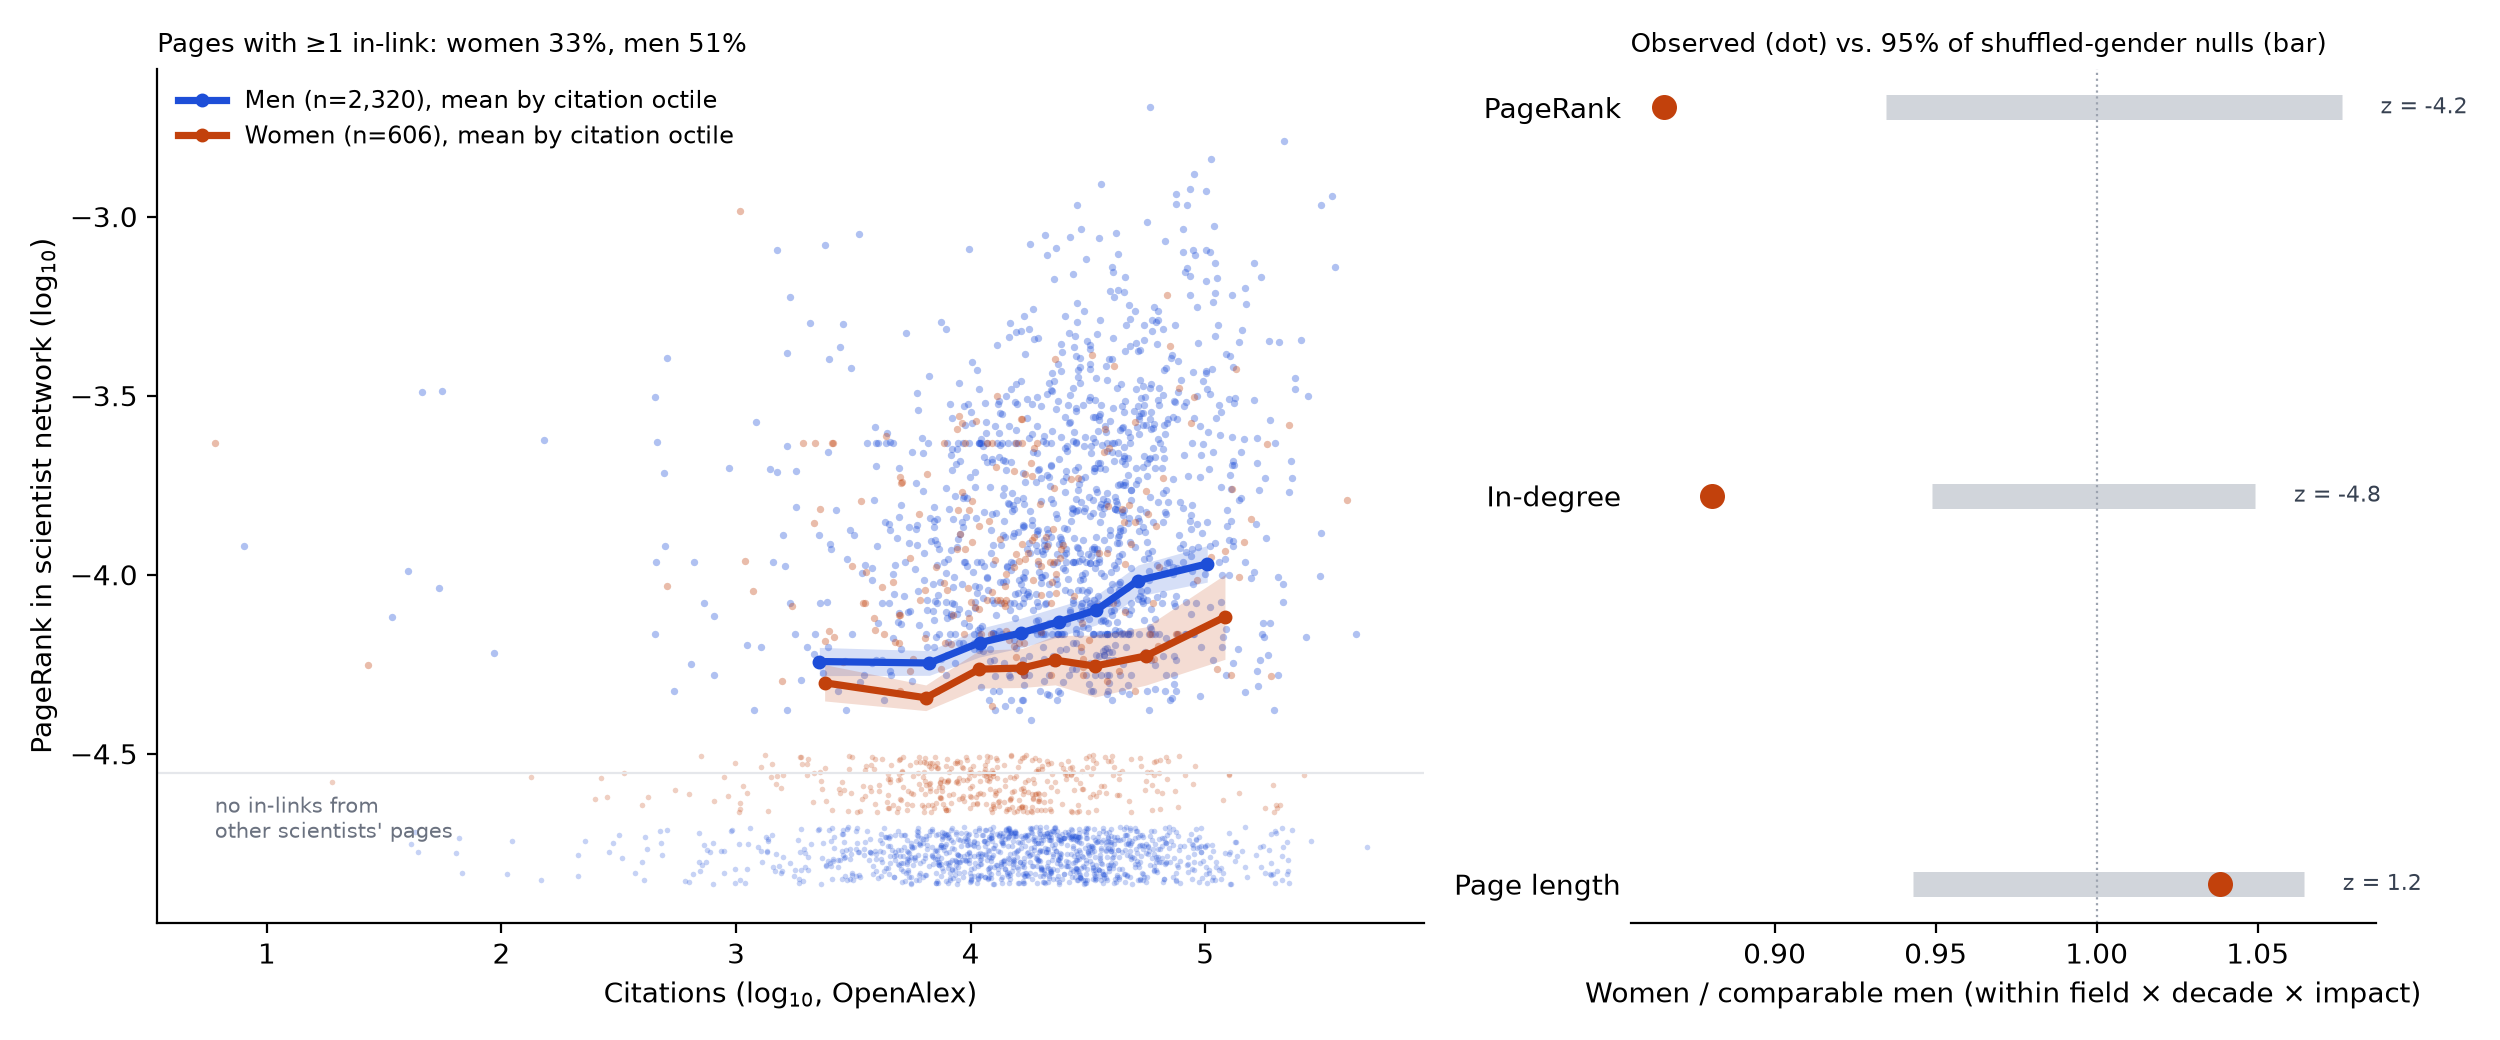

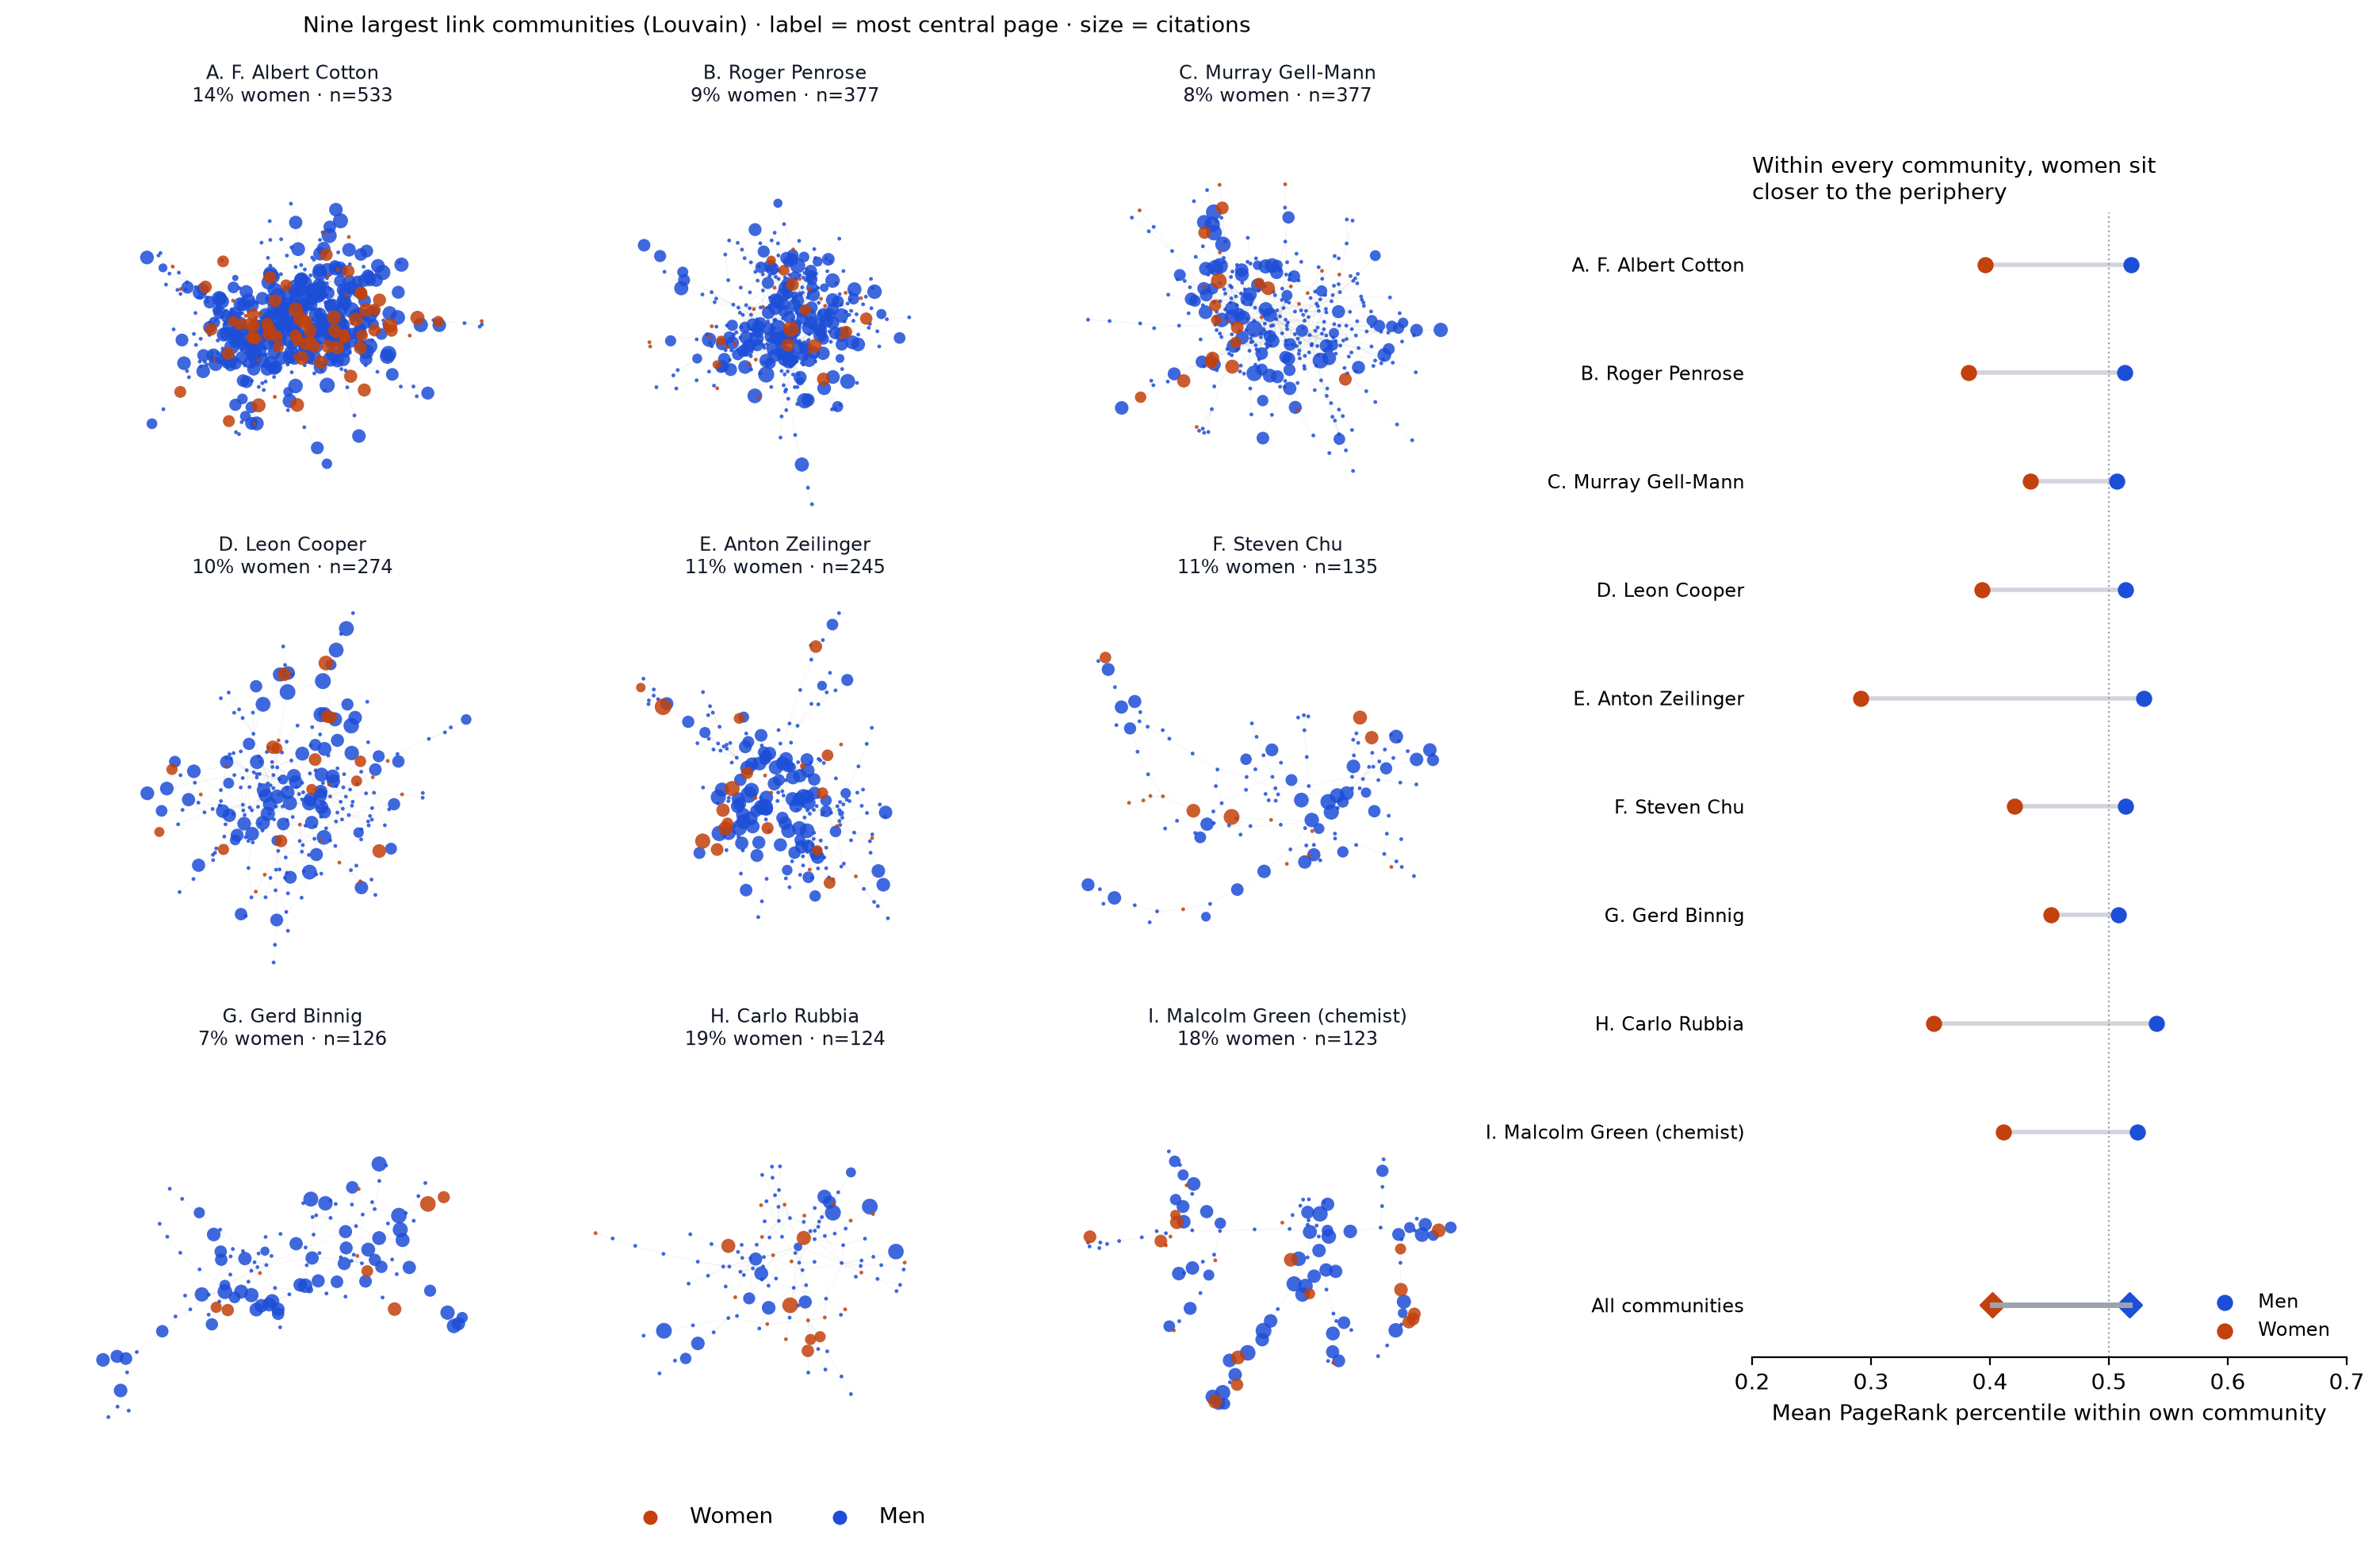

In [14]:
network_main([])
display(Image(str(FIG / 'fig1_main_citations_b5_s2805.png')))
display(Image(str(FIG / 'fig3_main.png')))

## 4 · Text analysis (RQ2)

* **Masking:** spaCy NER replaces person names; pronouns and gender words (and names of women-only awards) are masked; kinship words are made gender-neutral (husband/wife → spouse, …).
* **Word lists:** share of sentences with personal-life and professional words, regressed on gender with the same covariates plus page length.
* **Explicit gender mentions:** "first woman", "female physicist", …
* **Fightin' Words** (Monroe et al. 2008), adapted to document frequencies so one long page cannot dominate; checked within citation terciles and within each field. Figure 2a uses the Scattertext layout (Kessler 2017); the interactive version is in `results/fig2_scattertext.html`.
* **Validation:** 300 hand-labelled sentences (150 per gender), sampled by stratum (personal-flagged / professional-flagged / neither), give weighted precision and recall with bootstrap CIs.

In [15]:
import argparse
import json
import re
from collections import Counter

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.formula.api as smf
from tqdm import tqdm


RES, FIG = ROOT / "results", ROOT / "figures"
MASKED = PROC / "text_masked"
MASKED.mkdir(exist_ok=True)
COL = {"female": "#C2410C", "male": "#1D4ED8"}
SEED = 2805

PRONOUNS = r"she|he|her|hers|herself|him|his|himself"
GENDER_WORDS = (r"woman|women|man|men|female|females|male|males|girl|girls|boy|boys|lady|ladies|gentleman|"
                r"gentlemen|chairwoman|chairman|spokeswoman|spokesman|businesswoman|businessman|"
                r"sportswoman|sportsman|congresswoman|congressman")
TITLES = r"\b(Mrs|Mr|Ms|Miss|Madame|Mme|Mlle|Sir|Dame|Lady|Lord)\b\.?"  # case-sensitive: avoids MS (degree)
KIN = {"husband": "spouse", "wife": "spouse", "husbands": "spouses", "wives": "spouses",
       "son": "child", "daughter": "child", "sons": "children", "daughters": "children",
       "mother": "parent", "father": "parent", "mothers": "parents", "fathers": "parents",
       "brother": "sibling", "sister": "sibling", "brothers": "siblings", "sisters": "siblings",
       "grandmother": "grandparent", "grandfather": "grandparent", "niece": "nibling", "nephew": "nibling",
       "widow": "widowed", "widower": "widowed", "fiancee": "fiance", "fiancée": "fiance",
       "motherhood": "parenthood", "fatherhood": "parenthood", "maternity": "parental", "paternity": "parental",
       "stepson": "stepchild", "stepdaughter": "stepchild", "stepmother": "stepparent", "stepfather": "stepparent"}

PERSONAL = set("""married marry marriage marriages spouse spouses divorced divorce divorces widowed remarried
child children childless parent parents grandparent grandchildren sibling siblings family families pregnant
pregnancy parenthood parental childcare raised wedding fiance stepchild stepparent nibling""".split())
PROFESSIONAL = set("""research researched researcher discovered discovery discoveries theory theories theoretical
experiment experiments experimental published publication publications professor laboratory laboratories
developed invented invention award awarded prize medal fellow elected director founded patent patents
synthesis synthesized measured proposed pioneered pioneering led thesis dissertation doctorate phd postdoctoral
lecturer faculty department institute appointed collaborated collaboration journal papers""".split())
EXPLICIT = re.compile(r"\b(first|only)\s+(woman|women|female|man|male)\b|\b(woman|female|male)\s+"
                      r"(physicist|chemist|scientist|professor|researcher)s?\b", re.I)


# ---------------------------------------------------------------- 1. masking
def mask_all(qids):
    import spacy
    nlp = spacy.load("en_core_web_sm", disable=["tagger", "parser", "lemmatizer", "attribute_ruler"])
    nlp.add_pipe("sentencizer")
    nlp.max_length = 3_000_000
    todo = [q for q in qids if not (MASKED / f"{q}.txt").exists()]
    pron = re.compile(rf"\b({PRONOUNS})\b", re.I)
    gend = re.compile(rf"\b({GENDER_WORDS})\b", re.I)
    kin = re.compile(r"\b(" + "|".join(sorted(KIN, key=len, reverse=True)) + r")\b", re.I)
    texts = ((PROC / "text" / f"{q}.txt").read_text() for q in todo)
    for q, doc in tqdm(zip(todo, nlp.pipe(texts, batch_size=32)), total=len(todo), desc="mask", mininterval=20):
        sents = []
        for s in doc.sents:
            t, last = [], s.start_char
            for e in (e for e in doc.ents if e.label_ == "PERSON" and s.start_char <= e.start_char < s.end_char):
                t += [doc.text[last:e.start_char], "NAME"]
                last = e.end_char
            t.append(doc.text[last:s.end_char])
            x = "".join(t).replace("\n", " ").strip()
            x = pron.sub("PRON", x)
            x = gend.sub("GENDERWORD", x)
            x = re.sub(TITLES, "GENDERWORD", x)
            x = kin.sub(lambda m: KIN[m.group(1).lower()], x)
            if len(x.split()) >= 4:
                sents.append(x)
        (MASKED / f"{q}.txt").write_text("\n".join(sents))


GENDERED_ORGS = re.compile(
    r"L['’]?Or[ée]al[- ]?UNESCO|UNESCO[- ]L['’]?Or[ée]al|For GENDERWORD in Science|For Women in Science|"
    r"Association for (GENDERWORD|Women) in Science|(GENDERWORD|Women) in (Science|Physics|Chemistry|Engineering)|"
    r"Society of (GENDERWORD|Women) Engineers|(GENDERWORD|Women) Chemists Committee|Garvan[–-]Olin|"
    r"Maria Goeppert[- ]Mayer Award|Sigma Delta Epsilon|Mary Shepard B\. Upson|Agnes Fay Morgan|"
    r"Iota Sigma Pi|Committee on the Status of (GENDERWORD|Women) in Physics|CSWP|Emmy Noether Fellowship",
    re.I)


def unmask_safe(s):
    """Replace names of women-only awards/organisations, which would reveal gender, with ORGNAME."""
    return GENDERED_ORGS.sub("ORGNAME", s)


def tokens(s):
    return [w for w in re.findall(r"[a-z]{3,}", s.lower()) if w not in {"name", "pron", "genderword", "orgname"}]


# ---------------------------------------------------------------- 3. fightin' words
def fightin_words(docs_a, docs_b, min_docs=20, a0=10.0):
    """Log-odds with an informative prior (Monroe, Colaresi & Quinn 2008), adapted to document frequencies:
    for each word, the share of pages using it in group A vs. B (binomial), with a Beta prior centred on the
    pooled share and worth `a0` pseudo-pages. Shrinks rare words; a word every page uses scores ~0."""
    ca = Counter(w for d in docs_a for w in d)
    cb = Counter(w for d in docs_b for w in d)
    Na, Nb = len(docs_a), len(docs_b)
    vocab = [w for w in set(ca) | set(cb) if ca[w] + cb[w] >= min_docs]
    ya, yb = np.array([ca[w] for w in vocab], float), np.array([cb[w] for w in vocab], float)
    pi = (ya + yb) / (Na + Nb)
    al, be = a0 * pi + 0.5, a0 * (1 - pi) + 0.5  # +0.5 (Jeffreys) keeps words on every page finite
    la = np.log((ya + al) / (Na - ya + be))
    lb = np.log((yb + al) / (Nb - yb + be))
    var = 1 / (ya + al) + 1 / (Na - ya + be) + 1 / (yb + al) + 1 / (Nb - yb + be)
    delta = la - lb
    return pd.DataFrame({"word": vocab, "docs_women": ya, "docs_men": yb, "share_women": ya / Na,
                         "share_men": yb / Nb, "delta": delta, "z": delta / np.sqrt(var)}).sort_values("z")


# ---------------------------------------------------------------- 4. labelling
def label_sample(d, sents):
    rng = np.random.default_rng(SEED)
    rows = []
    for g in ("female", "male"):
        pool = [(q, i, s) for q in d.index[d.gender == g] for i, s in enumerate(sents[q])]
        strat = {"personal_flag": [], "professional_flag": [], "neither": []}
        for q, i, s in pool:
            t = set(tokens(s))
            k = "personal_flag" if t & PERSONAL else ("professional_flag" if t & PROFESSIONAL else "neither")
            strat[k].append((q, i, s))
        for k, xs in strat.items():
            for j in rng.choice(len(xs), min(50, len(xs)), replace=False):
                q, i, s = xs[j]
                rows.append({"qid": q, "sent_idx": i, "gender": g, "stratum": k, "stratum_pop": len(xs),
                             "sentence": s, "is_personal": "", "is_professional": ""})
    df = pd.DataFrame(rows).sample(frac=1, random_state=SEED)  # shuffle so labellers don't see strata in order
    return df


def validate(L, B=1000):
    """Weighted precision/recall for each list; strata weights = population / sample size."""
    rng = np.random.default_rng(SEED)
    out = {}
    for lst, flag_strata, col in (("personal", {"personal_flag"}, "is_personal"),
                                  ("professional", {"professional_flag"}, "is_professional")):
        def est(df):
            w = df.stratum_pop / df.groupby(["gender", "stratum"]).stratum.transform("size")
            pos = df[col].astype(int)
            flagged = df.stratum.isin(flag_strata)
            if lst == "professional":  # personal-flagged sentences also contain professional words sometimes
                flagged = flagged | df.sentence.map(lambda s: bool(set(tokens(s)) & PROFESSIONAL))
            tp = (w * pos * flagged).sum()
            return tp / max((w * flagged).sum(), 1e-9), tp / max((w * pos).sum(), 1e-9)
        p, r = est(L)
        groups = [idx.to_numpy() for idx in L.groupby(["gender", "stratum"]).groups.values()]

        def resample():  # bootstrap within each gender x stratum cell
            return L.loc[np.concatenate([rng.choice(g, len(g), replace=True) for g in groups])]
        boots = np.array([est(resample()) for _ in range(B)])
        out[lst] = {"precision": p, "precision_ci95": np.percentile(boots[:, 0], [2.5, 97.5]).tolist(),
                    "recall": r, "recall_ci95": np.percentile(boots[:, 1], [2.5, 97.5]).tolist(),
                    "n_labelled": len(L)}
        for g in ("female", "male"):
            pg, rg = est(L[L.gender == g])
            out[lst][f"precision_{g}"], out[lst][f"recall_{g}"] = pg, rg
    return out


# ---------------------------------------------------------------- figure 2
def fig2(fw, tab, ci, n_label=14):
    """(a) Scattertext-style plot (Kessler 2017): each word placed by how often it appears on men's pages (x)
    and women's pages (y), as dense frequency ranks scaled to 0-1. Words on the diagonal are used equally;
    the top-left corner is characteristic of women's pages, the bottom-right of men's.
    Colour = Fightin' Words z-score. (b) personal-life sentence share by citation quintile."""
    from adjustText import adjust_text
    from matplotlib.colors import LinearSegmentedColormap, TwoSlopeNorm

    f = fw.copy()
    f["x"] = f.share_men.rank(method="dense") / f.share_men.rank(method="dense").max()
    f["y"] = f.share_women.rank(method="dense") / f.share_women.rank(method="dense").max()
    cmap = LinearSegmentedColormap.from_list("mf", [COL["male"], "#E5E7EB", COL["female"]])
    lim = np.percentile(np.abs(f.z), 99.5)
    fig, (a, b) = plt.subplots(1, 2, figsize=(14, 6.4), gridspec_kw={"width_ratios": [1.15, 1]})
    a.scatter(f.x, f.y, c=f.z, cmap=cmap, norm=TwoSlopeNorm(0, -lim, lim), s=6, lw=0, alpha=0.8)
    a.plot([0, 1], [0, 1], color="#9CA3AF", lw=0.8, ls=":")
    lab = pd.concat([f.nlargest(n_label, "z"), f.nsmallest(n_label, "z")])
    texts = [a.text(r.x, r.y, r.word, fontsize=8, color=COL["female"] if r.z > 0 else COL["male"],
                    fontweight="bold") for r in lab.itertuples()]
    adjust_text(texts, ax=a, arrowprops=dict(arrowstyle="-", color="#9CA3AF", lw=0.5),
                expand=(1.3, 1.6), force_text=(0.4, 0.6))
    a.text(0.02, 0.98, "more typical of\nwomen's pages", transform=a.transAxes, va="top", fontsize=9,
           color=COL["female"])
    a.text(0.98, 0.02, "more typical of\nmen's pages", transform=a.transAxes, ha="right", fontsize=9,
           color=COL["male"])
    a.set_xlabel("Frequency on men's pages (rank, low → high)")
    a.set_ylabel("Frequency on women's pages (rank, low → high)")
    a.set_xlim(-0.02, 1.02)
    a.set_ylim(-0.02, 1.02)
    a.set_title("Words on women's vs. men's pages (names, pronouns, gender words masked)",
                fontsize=10, loc="left")
    a.spines[["top", "right"]].set_visible(False)

    xs = np.arange(tab.shape[0])
    for i, g in enumerate(("male", "female")):
        m = tab[g].to_numpy()
        lo, hi = ci[g][:, 0], ci[g][:, 1]
        b.bar(xs + (i - .5) * .38, m, .38, color=COL[g], label="Women" if g == "female" else "Men",
              yerr=[m - lo, hi - m], capsize=2, error_kw={"lw": .8})
    b.set_xticks(xs, [f"Q{i + 1}" for i in xs])
    b.set_xlabel("Citation quintile (low → high)")
    b.set_ylabel("Share of sentences with personal-life words")
    b.set_title("Personal-life sentences, by impact", fontsize=10, loc="left")
    b.legend(frameon=False)
    b.spines[["top", "right"]].set_visible(False)
    fig.tight_layout()
    fig.savefig(FIG / "fig2_text.png", dpi=200)
    plt.close(fig)


def scattertext_html(d, sents):
    """Interactive Scattertext explorer (supplement), on masked text."""
    import scattertext as st
    df = pd.DataFrame({"gender": np.where(d.female == 1, "Women", "Men"),
                       "text": [" ".join(" ".join(tokens(s)) for s in sents[q]) for q in d.index],
                       "title": d.title.to_numpy()})
    from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS
    corpus = (st.CorpusFromPandas(df, category_col="gender", text_col="text",
                                  nlp=st.whitespace_nlp_with_sentences).build()
              .get_unigram_corpus().remove_terms(list(ENGLISH_STOP_WORDS), ignore_absences=True))
    html = st.produce_scattertext_explorer(corpus, category="Women", category_name="Women's pages",
                                           not_category_name="Men's pages", minimum_term_frequency=20,
                                           metadata=df.title, width_in_pixels=1000)
    (RES / "fig2_scattertext.html").write_text(html)


def text_main(argv=None):
    ap = argparse.ArgumentParser()
    ap.add_argument("--validate", action="store_true", help="read hand labels and report precision/recall")
    ap.add_argument("--fields", default="main")
    a = ap.parse_args(argv)

    nodes = pd.read_csv(PROC / "nodes.csv").set_index("qid")
    d = nodes[nodes.usable & (nodes.main_field if a.fields == "main" else nodes.field_group == a.fields)].copy()
    mask_all(list(d.index))
    sents = {q: [unmask_safe(s) for s in (MASKED / f"{q}.txt").read_text().split("\n") if s] for q in d.index}

    # 2. word-list shares + explicit gender mentions
    rows = []
    for q in d.index:
        ss = sents[q]
        n = max(len(ss), 1)
        raw = (PROC / "text" / f"{q}.txt").read_text()
        rows.append({"qid": q, "n_sent": len(ss),
                     "share_personal": sum(bool(set(tokens(s)) & PERSONAL) for s in ss) / n,
                     "share_professional": sum(bool(set(tokens(s)) & PROFESSIONAL) for s in ss) / n,
                     "explicit_gender_mention": int(bool(EXPLICIT.search(raw)))})
    d = d.join(pd.DataFrame(rows).set_index("qid"))
    d["female"] = (d.gender == "female").astype(int)
    d["log_impact"] = np.log10(d.citations)
    d["log_words"] = np.log10(d.n_words)
    d["deceased"] = d.deceased.fillna(0)
    d["cit_q"] = pd.qcut(d.log_impact.rank(method="first"), 5, labels=False)
    d[["gender", "cit_q", "share_personal", "share_professional", "explicit_gender_mention", "n_sent"]].to_csv(
        RES / "rq2_page_scores.csv")

    out = {"n_pages": len(d), "women": int(d.female.sum()), "regression": {}}
    for y in ("share_personal", "share_professional", "explicit_gender_mention"):
        m = smf.ols(f"{y} ~ female + log_impact + C(field_group) + C(birth_decade) + deceased + log_words",
                    data=d).fit(cov_type="HC3")
        lo, hi = m.conf_int().loc["female"]
        out["regression"][y] = {"coef_female": m.params["female"], "ci95": [lo, hi], "p": m.pvalues["female"],
                                "mean_men": d.loc[d.female == 0, y].mean(), "mean_women": d.loc[d.female == 1, y].mean()}

    # per-quintile means with bootstrap CIs (Figure 2b)
    rng = np.random.default_rng(SEED)
    tab = d.groupby(["cit_q", "gender"]).share_personal.mean().unstack()
    ci = {g: np.array([np.percentile([rng.choice(v, len(v)).mean() for _ in range(1000)], [2.5, 97.5])
                       for v in (d[(d.cit_q == k) & (d.gender == g)].share_personal.to_numpy() for k in tab.index)])
          for g in ("female", "male")}
    out["share_personal_by_quintile"] = tab.round(4).to_dict()

    # 3. fightin' words (whole set + within citation terciles)
    docs = {q: set(w for s in sents[q] for w in tokens(s)) for q in d.index}
    fw = fightin_words([docs[q] for q in d.index[d.female == 1]], [docs[q] for q in d.index[d.female == 0]])
    d["cit_t"] = pd.qcut(d.log_impact.rank(method="first"), 3, labels=False)
    for t in range(3):
        s = d[d.cit_t == t]
        ft = fightin_words([docs[q] for q in s.index[s.female == 1]], [docs[q] for q in s.index[s.female == 0]],
                           min_docs=10).set_index("word").z
        fw[f"z_tercile{t + 1}"] = fw.word.map(ft)
    for fld in ("physics", "chemistry"):
        s_ = d[d.field_group == fld]
        ff = fightin_words([docs[q] for q in s_.index[s_.female == 1]], [docs[q] for q in s_.index[s_.female == 0]],
                           min_docs=10).set_index("word").z
        fw[f"z_{fld}"] = fw.word.map(ff)
    fw.to_csv(RES / "fightin_words.csv", index=False)
    top = pd.concat([fw.head(30), fw.tail(30)])
    both = fw.dropna(subset=["z_physics", "z_chemistry"])
    out["fightin_words_within_field"] = {
        "top60_same_sign_in_both_fields": float(np.mean(
            [np.sign(r.z_physics) == np.sign(r.z) == np.sign(r.z_chemistry) for _, r in
             pd.concat([both.head(30), both.tail(30)]).iterrows()])),
        "physics_top_women": fw.sort_values("z_physics").dropna(subset=["z_physics"]).tail(15).word.tolist()[::-1],
        "physics_top_men": fw.sort_values("z_physics").dropna(subset=["z_physics"]).head(15).word.tolist(),
        "chemistry_top_women": fw.sort_values("z_chemistry").dropna(subset=["z_chemistry"]).tail(15).word.tolist()[::-1],
        "chemistry_top_men": fw.sort_values("z_chemistry").dropna(subset=["z_chemistry"]).head(15).word.tolist()}
    out["fightin_words"] = {
        "top_women": fw.tail(25).word.tolist()[::-1], "top_men": fw.head(25).word.tolist(),
        "top60_same_sign_in_all_terciles": float(np.mean(
            [np.all(np.sign(r[[f"z_tercile{t}" for t in (1, 2, 3)]].astype(float)) == np.sign(r.z))
             for _, r in top.iterrows()]))}

    fig2(fw, tab, ci)
    scattertext_html(d, sents)

    # 4. hand labelling
    lab = RES / "sentences_to_label.csv"
    if not lab.exists():
        label_sample(d, sents).to_csv(lab, index=False)
        print(f"Wrote {lab}: fill is_personal and is_professional (1/0), then rerun with --validate")
    if a.validate:
        L = pd.read_csv(lab).dropna(subset=["is_personal", "is_professional"])
        out["validation"] = validate(L)

    (RES / "rq2_text.json").write_text(json.dumps(out, indent=2, default=float))
    log("analysis", "RQ2 text analysis", len(d))
    r = out["regression"]
    print(f"\nPages: {len(d)} ({out['women']} women)")
    for y, v in r.items():
        print(f"{y:<26} women {v['mean_women']:.4f} vs men {v['mean_men']:.4f} | adjusted diff "
              f"{v['coef_female']:+.4f} [{v['ci95'][0]:+.4f}, {v['ci95'][1]:+.4f}] p={v['p']:.3g}")
    print("Top women's-page words:", ", ".join(out["fightin_words"]["top_women"][:15]))
    print("Top men's-page words:  ", ", ".join(out["fightin_words"]["top_men"][:15]))
    w = out["fightin_words_within_field"]
    print(f"Within field, top-60 same sign in physics and chemistry: {w['top60_same_sign_in_both_fields']:.0%}")
    for k in ("physics_top_women", "physics_top_men", "chemistry_top_women", "chemistry_top_men"):
        print(f"  {k:<22}", ", ".join(w[k][:12]))
    print(f"Top-60 words same sign in all citation terciles: {out['fightin_words']['top60_same_sign_in_all_terciles']:.0%}")


mask: 0it [00:00, ?it/s]

mask: 0it [00:00, ?it/s]


Pages: 2926 (606 women)
share_personal             women 0.0307 vs men 0.0289 | adjusted diff +0.0053 [+0.0002, +0.0103] p=0.0398
share_professional         women 0.6131 vs men 0.6210 | adjusted diff -0.0066 [-0.0210, +0.0079] p=0.373
explicit_gender_mention    women 0.1551 vs men 0.0013 | adjusted diff +0.1661 [+0.1354, +0.1967] p=2.52e-26
Top women's-page words: education, career, completed, earned, considers, recognition, nomination, interested, postdoctoral, earning, moved, life, gender, young, fellowship
Top men's-page words:   theory, received, known, emeritus, quantum, books, papers, among, visiting, theoretical, now, under, biography, born, press
Within field, top-60 same sign in physics and chemistry: 98%
  physics_top_women      education, completed, recognition, career, nomination, postdoctoral, earned, earning, curie, researcher, moved, considers
  physics_top_men        theory, received, books, called, quantum, theoretical, field, papers, other, introduced, theories, mech

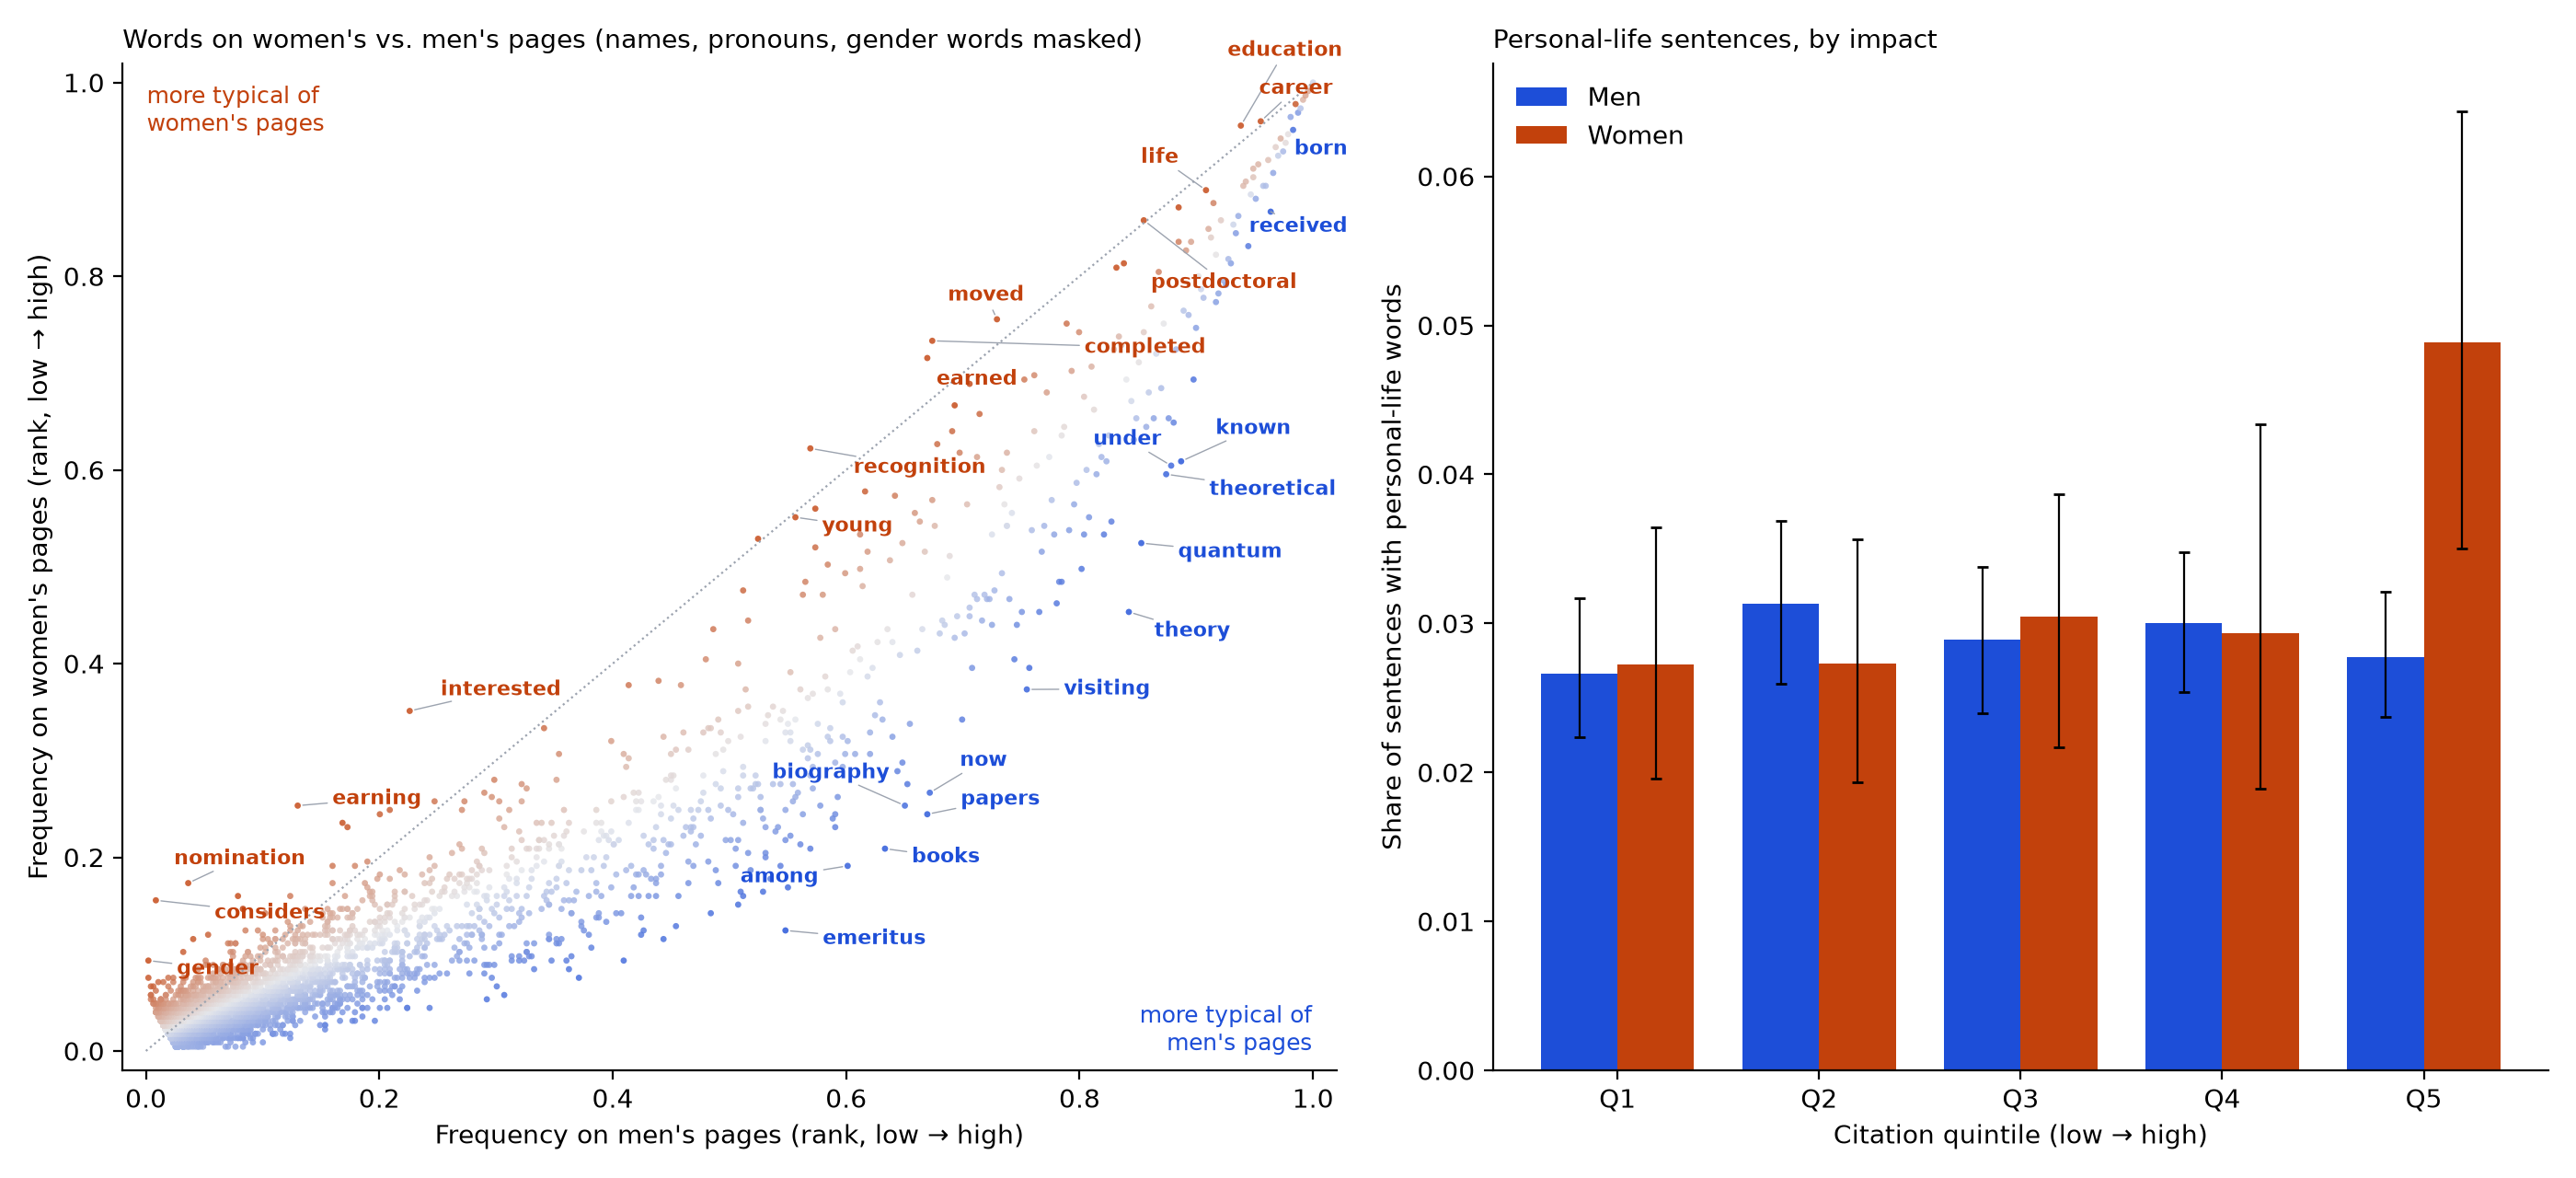

In [16]:
text_main(['--validate'])
display(Image(str(FIG / 'fig2_text.png')))

## 5 · Robustness

RQ1 repeated with 3 or 10 impact bins, other shuffle seeds, h-index or works instead of citations, without Nobel laureates, without the top 1% by impact, and in a second field (biology). Ratio = women's outcome as a multiple of comparable men's (geometric means); a value below 1 means less visible.

In [17]:
import argparse

import pandas as pd


RES = ROOT / "results"

CONFIGS = [
    ("Main (citations, 5 bins)", dict()),
    ("3 impact bins", dict(bins=3)),
    ("10 impact bins", dict(bins=10)),
    ("Seed 1", dict(seed=1)),
    ("Seed 2", dict(seed=2)),
    ("Impact = h-index", dict(impact="h_index")),
    ("Impact = works", dict(impact="works")),
    ("Without Nobel laureates", dict(drop_nobel=True)),
    ("Without top 1% impact", dict(drop_top1=True)),
    ("Without Nobel and top 1%", dict(drop_nobel=True, drop_top1=True)),
    ("Biology (second field)", dict(fields="biology")),
]


def robustness_main(argv=None):
    ap = argparse.ArgumentParser()
    ap.add_argument("--runs", type=int, default=500)
    a = ap.parse_args(argv)
    cache, rows = {}, []
    for name, cfg in CONFIGS:
        fields = cfg.get("fields", "main")
        if fields not in cache:
            cache[fields] = load_graph(fields)
        out, _ = run_rq1(runs=a.runs, nodes_G=cache[fields], **cfg)
        for col, s in out["shuffle"].items():
            r = out["regression"][col]
            rows.append({"variant": name, "outcome": col, "n": s["n"], "women": s["women"],
                         "shuffle_ratio": s["gap_ratio"], "z": s["z"], "p": s["p"],
                         "reg_ratio": r["ratio"], "reg_lo": r["ratio_ci95"][0], "reg_hi": r["ratio_ci95"][1],
                         "reg_ratio_with_prizes": out["regression_with_prizes"][col]["ratio"]})
        print(f"done: {name}")
    df = pd.DataFrame(rows)
    df.to_csv(RES / "robustness.csv", index=False)

    lines = ["| Variant | Outcome | n (women) | Shuffle ratio (z) | Regression ratio [95% CI] | + prizes |",
             "|---|---|---|---|---|---|"]
    for r in df.itertuples():
        lines.append(f"| {r.variant} | {r.outcome} | {r.n} ({r.women}) | {r.shuffle_ratio:.2f} ({r.z:+.1f}) | "
                     f"{r.reg_ratio:.2f} [{r.reg_lo:.2f}, {r.reg_hi:.2f}] | {r.reg_ratio_with_prizes:.2f} |")
    lines.append("\nRatio = women's outcome as a multiple of comparable men's (geometric means); < 1 = less visible.")
    (RES / "robustness.md").write_text("\n".join(lines) + "\n")
    log("analysis", "robustness table", len(df))
    print(pd.pivot_table(df, index="variant", columns="outcome", values="reg_ratio").round(2).to_string())


In [18]:
robustness_main([])
display(Markdown((RES / 'robustness.md').read_text()))

done: Main (citations, 5 bins)


done: 3 impact bins


done: 10 impact bins


done: Seed 1


done: Seed 2


done: Impact = h-index


... (5 outputs left out)

/var/folders/zl/3phk_sls0nz009rxnw5kqy5r0000gn/T/ipykernel_31589/461771725.py:103: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  m = smf.ols(f, data=d.dropna(subset=[y])).fit(cov_type="HC3")
/var/folders/zl/3phk_sls0nz009rxnw5kqy5r0000gn/T/ipykernel_31589/461771725.py:103: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  m = smf.ols(f, data=d.dropna(subset=[y])).fit(cov_type="HC3")


/var/folders/zl/3phk_sls0nz009rxnw5kqy5r0000gn/T/ipykernel_31589/461771725.py:103: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  m = smf.ols(f, data=d.dropna(subset=[y])).fit(cov_type="HC3")


done: Without Nobel and top 1%
done: Biology (second field)
outcome                   in_degree  n_words  pagerank
variant                                               
10 impact bins                 0.87     1.02      0.85
3 impact bins                  0.87     1.02      0.85
Biology (second field)         0.96     1.22      0.95
Impact = h-index               0.86     1.02      0.84
Impact = works                 0.83     1.01      0.81
Main (citations, 5 bins)       0.87     1.02      0.85
Seed 1                         0.87     1.02      0.85
Seed 2                         0.87     1.02      0.85
Without Nobel and top 1%       0.87     1.02      0.86
Without Nobel laureates        0.87     1.02      0.87
Without top 1% impact          0.87     1.02      0.86


| Variant | Outcome | n (women) | Shuffle ratio (z) | Regression ratio [95% CI] | + prizes |
|---|---|---|---|---|---|
| Main (citations, 5 bins) | pagerank | 2926 (606) | 0.87 (-4.3) | 0.85 [0.80, 0.91] | 0.82 |
| Main (citations, 5 bins) | in_degree | 2926 (606) | 0.88 (-4.7) | 0.87 [0.83, 0.91] | 0.84 |
| Main (citations, 5 bins) | n_words | 2926 (606) | 1.04 (+1.1) | 1.02 [0.96, 1.09] | 0.99 |
| 3 impact bins | pagerank | 2926 (606) | 0.86 (-4.2) | 0.85 [0.80, 0.91] | 0.82 |
| 3 impact bins | in_degree | 2926 (606) | 0.87 (-4.9) | 0.87 [0.83, 0.91] | 0.84 |
| 3 impact bins | n_words | 2926 (606) | 1.02 (+0.7) | 1.02 [0.96, 1.09] | 0.99 |
| 10 impact bins | pagerank | 2926 (606) | 0.87 (-3.8) | 0.85 [0.80, 0.91] | 0.82 |
| 10 impact bins | in_degree | 2926 (606) | 0.88 (-5.0) | 0.87 [0.83, 0.91] | 0.84 |
| 10 impact bins | n_words | 2926 (606) | 1.05 (+1.6) | 1.02 [0.96, 1.09] | 0.99 |
| Seed 1 | pagerank | 2926 (606) | 0.87 (-4.1) | 0.85 [0.80, 0.91] | 0.82 |
| Seed 1 | in_degree | 2926 (606) | 0.88 (-4.6) | 0.87 [0.83, 0.91] | 0.84 |
| Seed 1 | n_words | 2926 (606) | 1.04 (+1.2) | 1.02 [0.96, 1.09] | 0.99 |
| Seed 2 | pagerank | 2926 (606) | 0.87 (-4.2) | 0.85 [0.80, 0.91] | 0.82 |
| Seed 2 | in_degree | 2926 (606) | 0.88 (-4.8) | 0.87 [0.83, 0.91] | 0.84 |
| Seed 2 | n_words | 2926 (606) | 1.04 (+1.1) | 1.02 [0.96, 1.09] | 0.99 |
| Impact = h-index | pagerank | 2926 (606) | 0.85 (-4.7) | 0.84 [0.79, 0.90] | 0.82 |
| Impact = h-index | in_degree | 2926 (606) | 0.87 (-5.3) | 0.86 [0.81, 0.90] | 0.83 |
| Impact = h-index | n_words | 2926 (606) | 1.02 (+0.7) | 1.02 [0.96, 1.08] | 0.99 |
| Impact = works | pagerank | 2926 (606) | 0.83 (-5.0) | 0.81 [0.76, 0.87] | 0.80 |
| Impact = works | in_degree | 2926 (606) | 0.85 (-5.9) | 0.83 [0.79, 0.87] | 0.82 |
| Impact = works | n_words | 2926 (606) | 1.02 (+0.5) | 1.01 [0.95, 1.07] | 0.99 |
| Without Nobel laureates | pagerank | 2830 (600) | 0.88 (-4.1) | 0.87 [0.81, 0.92] | 0.83 |
| Without Nobel laureates | in_degree | 2830 (600) | 0.89 (-4.7) | 0.87 [0.83, 0.92] | 0.84 |
| Without Nobel laureates | n_words | 2830 (600) | 1.04 (+1.1) | 1.02 [0.96, 1.08] | 0.99 |
| Without top 1% impact | pagerank | 2896 (603) | 0.87 (-4.1) | 0.86 [0.80, 0.91] | 0.82 |
| Without top 1% impact | in_degree | 2896 (603) | 0.88 (-4.7) | 0.87 [0.83, 0.91] | 0.84 |
| Without top 1% impact | n_words | 2896 (603) | 1.04 (+1.1) | 1.02 [0.96, 1.08] | 0.99 |
| Without Nobel and top 1% | pagerank | 2801 (597) | 0.88 (-3.9) | 0.86 [0.81, 0.92] | 0.83 |
| Without Nobel and top 1% | in_degree | 2801 (597) | 0.89 (-4.7) | 0.87 [0.83, 0.91] | 0.84 |
| Without Nobel and top 1% | n_words | 2801 (597) | 1.03 (+0.9) | 1.02 [0.96, 1.08] | 0.98 |
| Biology (second field) | pagerank | 1030 (344) | 0.94 (-2.0) | 0.95 [0.89, 1.02] | 0.93 |
| Biology (second field) | in_degree | 1030 (344) | 0.95 (-2.3) | 0.96 [0.92, 1.00] | 0.94 |
| Biology (second field) | n_words | 1030 (344) | 1.22 (+3.8) | 1.22 [1.11, 1.33] | 1.16 |

Ratio = women's outcome as a multiple of comparable men's (geometric means); < 1 = less visible.


## 6 · Summary of results (13 Nov 2026 run)

| | Result |
|---|---|
| **RQ1** | At equal citations, field and decade, women's pages have **~14% lower PageRank** (ratio 0.86, z = −4.2) and ~12% lower in-degree. Page length does not differ. |
| Two parts | Only **33%** of women's pages get any link from another scientist's page, against **51%** of men's (adjusted −9 points); among linked pages, PageRank is still ~11% lower. |
| Robustness | The gap holds without Nobel laureates, without the top 1%, and with h-index or works. In **biology** it is smaller (0.95, borderline), and women's pages there are 22% longer. |
| **RQ3** | 22% of in-links to women's pages come from women, against 16% expected (z = 4.3). Within every large community, women sit closer to the periphery (PageRank percentile 0.40 vs 0.52; women rank lower in ≥ 98% of community × seed cases. Louvain partitions vary slightly between runs, so the exact count changes, but the pattern does not). |
| **RQ2** | 15.5% of women's pages mention their gender explicitly, against 0.1% of men's. Women's pages lean on career path (*education, career, completed, earned*) and men's on the work (*theory, papers, known*); 98% of the top words lean the same way in physics and chemistry. |
| Caveat | The personal-life word list has high precision (0.92) but low recall (0.36), and the recall is higher on women's pages, so the small personal-life difference (+0.5 points) is **not** a reliable finding. |
| Data quality | Hand-check: 100/100 matches correct; OpenAlex profile complete for 98% of women and 94% of men. |

*Numbers are from the run recorded in `data/data_log.csv`; re-running the cells above reproduces them.*